# Lending Game — Part 2: Predicting the probability of default

**We are lender 3.** This notebook estimates the probability that a loan applicant defaults,
under five *information sets*, i.e. five choices of which private signals the model may use:

| information set | variables | why we need it |
|---|---|---|
| **own** | public variables + `signal3` | **our model**: the only one we can apply to the new applicants |
| **full** | public variables + `signal1`, `signal2`, `signal3` | benchmark: the best prediction anyone could make |
| **lender1** | public variables + `signal1` | our best guess of lender 1's model |
| **lender2** | public variables + `signal2` | our best guess of lender 2's model |
| **public** | public variables only | baseline: how much a private signal is worth |

The notebook applies the same protocol to all five information sets models (explained is sections 1-5). Section 6 compares the models and information sets and concludes.

The public variables are `sex`, `employment`, `married` and `income`. For each information set we
train three models, interpret them, check their calibration and validate them:

* **logistic regression** — linear in the log-odds; transparent, the benchmark;
* **spline logistic regression** — the same model, but income and each signal enter through a smooth
  curve (cubic spline) instead of a straight line; still additive and explainable;
* **gradient boosting** — an ensemble of small decision trees; captures non-linearities and
  interactions without being told where they are.

The break-even rate of Part 3 is
$r = p / (1 - p)$: we price on the *level* of $p$, not only on the ranking of applicants.
A model that ranks well (high AUC) but is off by a couple of points in $p$ misprices every loan.
We therefore select models on **log-loss**, which rewards both, and check calibration explicitly.

**Protocol:**

1. Data: Part 1's prep functions and its 80/20 split stratified on `default` (`SEED = 42`).
   80,000 training loans, 20,000 validation loans.
2. Training set only: 5-fold cross-validation with the same folds for every model and information
   set. Each training loan gets an **out-of-fold (OOF)** prediction from a model that never saw it.
   Model comparison and selection use OOF predictions.
3. Each model is then refitted on the whole training set and predicts the validation set **once**.
   Validation confirms the selection.
4. Our selected model predicts the 100,000 new applications.

Reusable code is in `src/`: `models.py` (data, features, models, cross-validation),
`evaluation.py` (metrics, calibration, bootstrap) and `model_plots.py` (interpretation and plots).

### How to read the metrics

| metric | meaning |
|---|---|
| `auc` | probability that a defaulter is ranked riskier than a non-defaulter (ranking only). It is better when it's higher. |
| `logloss` | average penalty $-[y\log p + (1-y)\log(1-p)]$; punishes bad ranking *and* bad probability levels. It is better when it's lower. |
| `logloss_skill` | share of the log-loss removed compared with predicting the average default rate for everyone. It is better when it's higher. |
| `brier` | mean squared error $(p - y)^2$ . It is better when it's lower.| 
| `calib_slope`, `calib_intercept` | fit of $\text{logit}(\text{default}) = a + b\,\text{logit}(p)$; perfect calibration is $b = 1$, $a = 0$. $b < 1$: predictions too extreme. It is better when: $b \approx 1$, $a \approx 0$ |
| `mean_pred` vs `default_rate` | average predicted vs observed default rate. It is better when they're equal. |

## 0. Setup

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import SEED
from src.data_prep import TARGET
from src.models import (INFORMATION_SETS, MODEL_FACTORIES, feature_columns, load_data,
                        get_X, get_y, make_folds, oof_predict_all, fit_models,
                        predict_default, fit_calibrator, save_predictions)
from src import evaluation as ev
from src import model_plots as mp

mp.set_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 200)

# Columns shown in the metric tables
METRICS = ["auc", "logloss", "logloss_skill", "brier", "calib_slope", "calib_intercept",
           "mean_pred", "default_rate"]

**Data.** `load_data()` rebuilds the prepared data from the raw files with Part 1's functions
(`logreg_prep_data` for the two logistic models, `boosting_prep_data` for boosting) and Part 1's
split, exactly as section 9 of `eda.ipynb` does. Both versions contain the same loans in the same
order, so out-of-fold and validation predictions line up loan by loan (`row_id`).

In [2]:
data = load_data()
y_train = get_y(data, "train")
y_val = get_y(data, "validation")

print(f"training set   : {len(y_train):>6,} loans, default rate {y_train.mean():.3%}")
print(f"validation set : {len(y_val):>6,} loans, default rate {y_val.mean():.3%}")
print(f"applications   : {len(data['logreg']['applications']):>6,} applicants (signal3 only, no outcome)")

# One set of folds for every model and every information set.
folds = make_folds(y_train)
print(f"\n{len(folds)} stratified folds of the training set, default rate per held-out fold:",
      [f"{y_train.iloc[test].mean():.3%}" for _, test in folds])

# Results collected section by section, combined in section 6.
OOF, VAL, FITTED, IMPORTANCE, CURVES = {}, {}, {}, {}, {}

training set   : 80,000 loans, default rate 9.947%
validation set : 20,000 loans, default rate 9.945%
applications   : 100,000 applicants (signal3 only, no outcome)

5 stratified folds of the training set, default rate per held-out fold: ['9.944%', '9.944%', '9.950%', '9.950%', '9.950%']


**Features per model** (from `PUBLIC_FEATURES` in `src/models.py`, following the EDA):

* *logistic*: `sex_F`, `married`, three employment dummies (employed is the reference),
  `income_log1p` and its square, `income_zero`, `unemployed_x_income_zero`;
* *spline logistic*: the same without the square — the spline on `income_log1p` already bends;
  the spline is applied to `income_log1p` and to each signal;
* *gradient boosting*: `sex_F`, `married`, the four employment dummies, raw `income`, `income_zero`
  (trees are unaffected by monotone transforms such as the log).

Each signal enters as its raw value plus a flag `signalk_missing` (1 when the lender received no
signal, which the EDA showed means "not scored", not "lowest score").

---

## 1. `own` — our model: public variables + signal 3


This is **our model**. When a new applicant arrives we observe the four public variables and our own
private signal `signal3`, nothing else, so this is the only model we can apply to the new
applications. Every price we set in Parts 3 to 8 starts from these predictions.

### 1.1 Features

In [3]:
INFO = "own"
for name in MODEL_FACTORIES:
    cols = feature_columns(name, INFO)
    print(f"{mp.MODEL_LABELS[name]:<18} ({len(cols):>2}) {', '.join(cols)}")

Logistic           (11) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_log1p_sq, income_zero, unemployed_x_income_zero, signal3, signal3_missing
Spline logistic    (10) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_zero, unemployed_x_income_zero, signal3, signal3_missing
Gradient boosting  (10) sex_F, married, employment_employed, employment_retired, employment_student, employment_unemployed, income, income_zero, signal3, signal3_missing


### 1.2 Training: out-of-fold predictions

Each model is trained 5 times, each time on 4 folds, and predicts the 5th. The table compares the
three models on the 80,000 out-of-fold predictions, best log-loss first.

In [4]:
OOF[INFO] = (oof_predict_all(data, folds, info_sets=[INFO])
             .rename(columns=lambda c: c.split("__")[1]))
oof_table = ev.compare_models(y_train, OOF[INFO])[METRICS]
oof_table.rename(index=mp.MODEL_LABELS)

,auc,logloss,logloss_skill,brier,calib_slope,calib_intercept,mean_pred,default_rate
Spline logistic,0.7357,0.2904,0.1036,0.0837,0.9950,-0.0094,0.0995,0.0995
Gradient boosting,0.7355,0.2906,0.1028,0.0837,1.0122,0.0224,0.0995,0.0995
Logistic,0.7351,0.2909,0.1019,0.0838,1.0077,0.0147,0.0995,0.0995


### 1.3 What each model has learned

All three models are refitted on the whole training set.

**Logistic regression coefficients.** Bars are standardized coefficients: the change in the
log-odds of default for a one-standard-deviation increase of the variable (positive = riskier).
`odds_ratio` is per one unit; for a 0/1 variable it is how the odds of default change when the
variable switches from 0 to 1. `income_log1p` and its square must be read together (see the
income curve below), not one by one.

,std_coef,raw_coef,odds_ratio
income_log1p,4.1595,1.1396,3.1256
income_zero,0.4010,1.0666,2.9054
sex_F,-0.0171,-0.0346,0.9660
unemployed_x_income_zero,-0.0292,-0.1151,0.8913
married,-0.0378,-0.0775,0.9254
employment_unemployed,-0.0686,-0.1955,0.8224
employment_student,-0.2411,-0.6557,0.5191
signal3_missing,-0.2571,-0.6298,0.5327
employment_retired,-0.2813,-0.8756,0.4166
signal3,-0.4323,-1.3294,0.2646


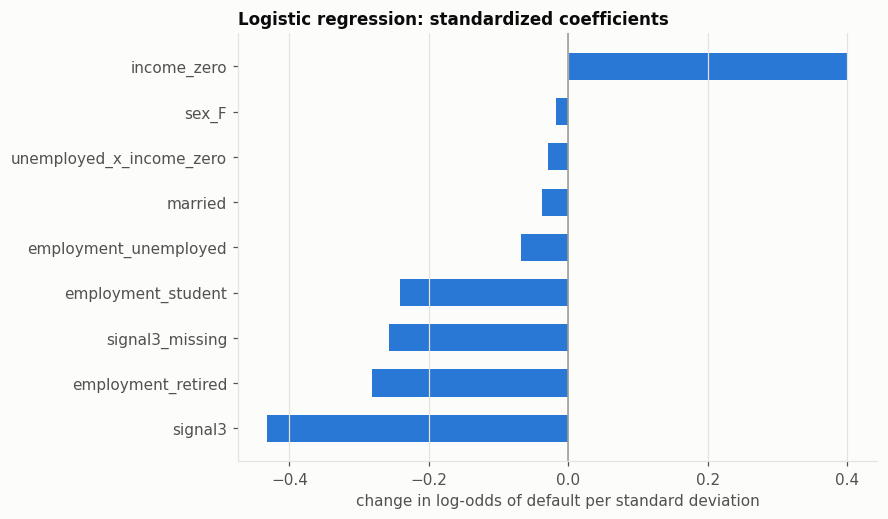

In [5]:
FITTED[INFO] = fit_models(data, INFO)
coefs = mp.logit_coefficients(FITTED[INFO]["logit"], feature_columns("logit", INFO))
display(coefs.sort_values("std_coef", ascending=False))
# income_log1p and its square are left out of the chart (see the income curve below).

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(coefs) + 1.2))
mp.plot_logit_coefficients(coefs, ax)
plt.show()

**Which variables each model relies on (permutation importance).** One variable at a time is
shuffled across loans, which destroys its information while keeping its distribution, and we
measure how much worse the log-loss gets. Related columns are shuffled together (e.g. income,
log income, income-zero flag and interaction; a signal and its missing flag). Measured on a
held-out fold the models were not trained on. This works the same way for all three models, so it
is the fair way to compare what they use.

,Logistic,Spline logistic,Gradient boosting
income,33.23,33.99,28.46
signal3,3.37,3.38,3.31
employment,3.34,2.87,1.79
married,0.04,0.04,-0.00
sex,-0.01,-0.01,0.03


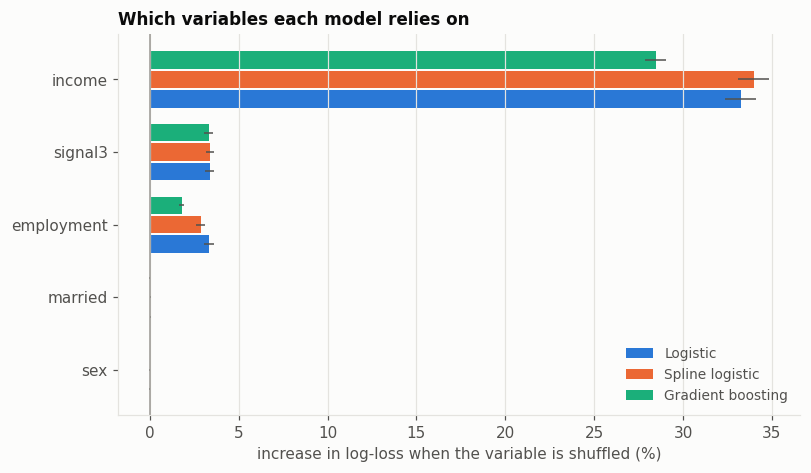

In [6]:
IMPORTANCE[INFO] = mp.holdout_importance(data, INFO, folds)
display(pd.concat({mp.MODEL_LABELS[m]: t["increase_pct"] for m, t in IMPORTANCE[INFO].items()},
                  axis=1).round(2))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(IMPORTANCE[INFO]["logit"]) + 1.5))
mp.plot_permutation_importance(IMPORTANCE[INFO], ax)
plt.show()

**How predicted risk moves with income and with the signal (partial dependence).** For 3,000
training loans, we set income (or the signal) to the same value for everyone and average the
predicted default probability; repeating over a grid of values traces the effect of that variable
with the others held at their observed values. The `none` marker is the prediction when the
lender received no signal. The dashed line is the average default rate.

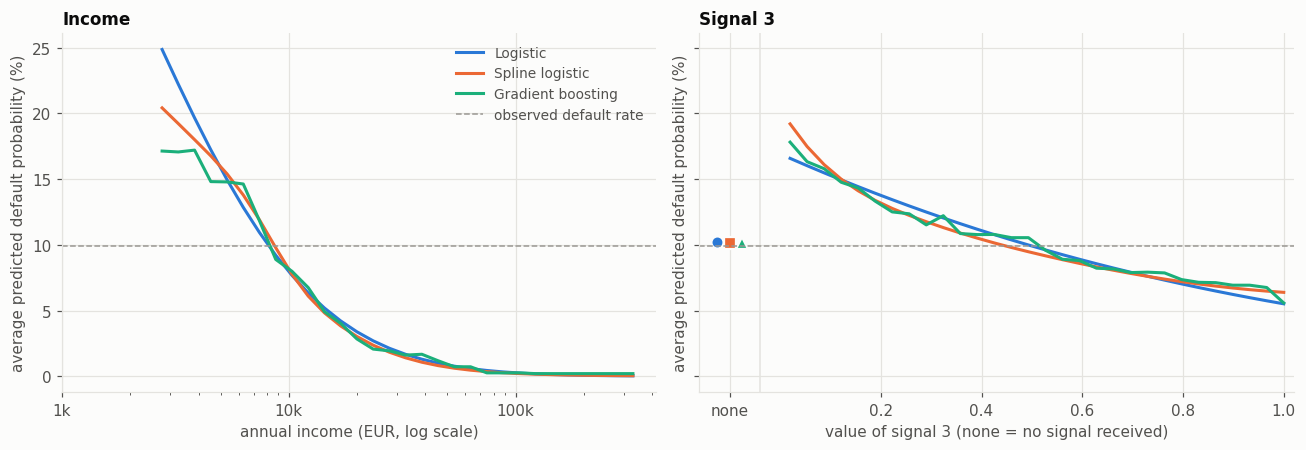

In [7]:
CURVES[INFO] = mp.dependence_curves(FITTED[INFO], data, INFO)
mp.plot_dependence_panels(CURVES[INFO], base_rate=y_train.mean())
plt.show()

**What the three models learned (own information set)**

* **Income dominates everything.** Shuffling income makes the log-loss 28-34% worse, roughly ten
  times more than any other variable. Predicted risk falls from about 17-25% for the lowest positive
  incomes (around EUR 3k a year) to the average 10% near EUR 9k, and below 1% above EUR 60k. Having
  no income at all (`income_zero`) adds risk on top of that: in the logistic regression it multiplies
  the odds of default by 2.9.
* **Our signal is the second most useful variable** (about 3.4% log-loss increase when shuffled), on
  a par with employment status. A higher signal means a safer borrower: predicted risk goes from
  about 17-19% at the lowest signal values to about 6% at the highest. The spline and boosting
  models bend, with a steeper drop for low signals and a flatter section above roughly 0.5, the
  shape found in the EDA. The logistic regression can only draw a straight line in the log-odds.
* **No signal means average risk, not high risk.** When `signal3` is missing, all three models
  predict about the average default rate (the `none` markers, about 10%). In the logistic
  regression, `signal3_missing` (-0.63 in log-odds) offsets the effect of the signal being 0, so a
  missing signal is treated like a signal of about 0.47 (0.63 / 1.33), close to the middle of its
  range. This confirms the EDA's reading of signal = 0 as "not scored".
* **Employment, once income is known.** Retired applicants and students are *less* risky than
  employed ones with the same income (odds ratios 0.42 and 0.52). The high raw default rates of
  students and the unemployed come through their low or zero income, not their status as such.
* **Sex and marital status carry almost no information** once income and employment are known
  (permutation importance about 0).
* **Where the models differ.** At the lowest positive incomes, the logistic regression predicts more
  risk (about 25% at EUR 3k) than the spline (about 20%) and boosting (about 17%): the square of log income keeps
  curving upward at the edge of the data. Boosting is flat there because trees cannot extrapolate.
  Boosting draws step-shaped curves, the spline smooth ones; in the middle of the data they agree.

### 1.4 Calibration

Left: loans are sorted into 10 equal-sized groups by predicted probability; each point compares
the group's average prediction with its observed default rate. On the dashed diagonal, a predicted
10% really means 10%. Right: how spread out the predictions are. A model that separates risk well
puts more loans far from the average.

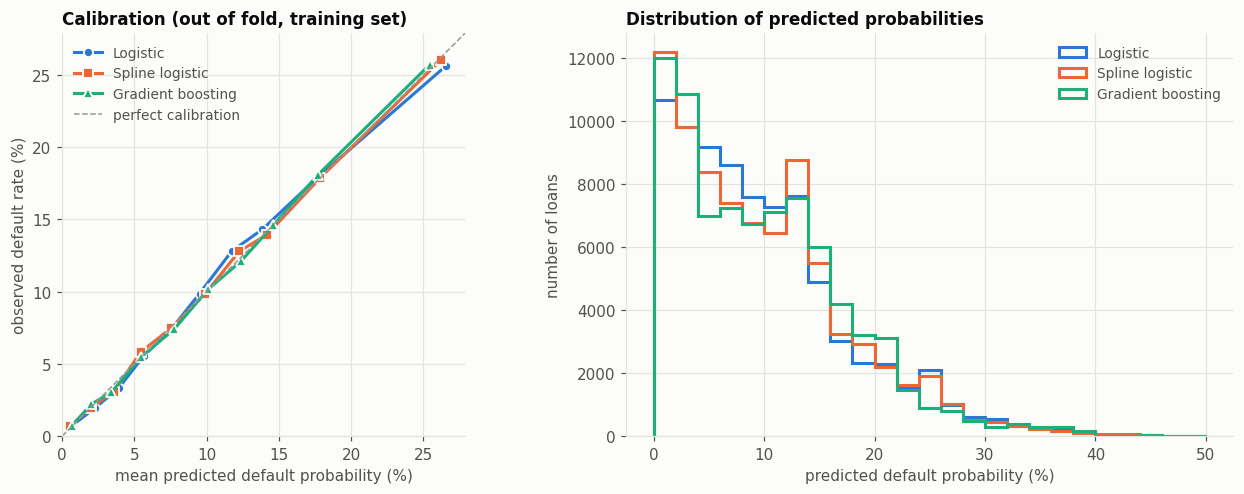

Predicted default probability, quantiles (out of fold):


,Logistic,Spline logistic,Gradient boosting
0.010000,0.10%,0.09%,0.15%
0.100000,1.47%,1.22%,1.50%
0.250000,3.90%,3.58%,3.41%
0.500000,8.43%,8.69%,8.96%
0.750000,13.79%,14.09%,14.61%
0.900000,20.82%,20.55%,20.26%
0.990000,33.33%,33.36%,33.95%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp.plot_reliability(y_train, OOF[INFO], axes[0],
                    title="Calibration (out of fold, training set)")
mp.plot_prediction_distribution(OOF[INFO], axes[1])
fig.tight_layout()
plt.show()

print("Predicted default probability, quantiles (out of fold):")
display(OOF[INFO].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
        .rename(columns=mp.MODEL_LABELS).style.format("{:.2%}"))

### 1.5 Validation

The models fitted on the whole training set predict the 20,000 validation loans, which no model
or choice has used so far.

out of fold (train)                     validation                    
                                  auc logloss calib_slope        auc logloss calib_slope
Spline logistic                0.7357  0.2904      0.9950     0.7360  0.2909      0.9909
Gradient boosting              0.7355  0.2906      1.0122     0.7364  0.2909      1.0002
Logistic                       0.7351  0.2909      1.0077     0.7346  0.2915      1.0027

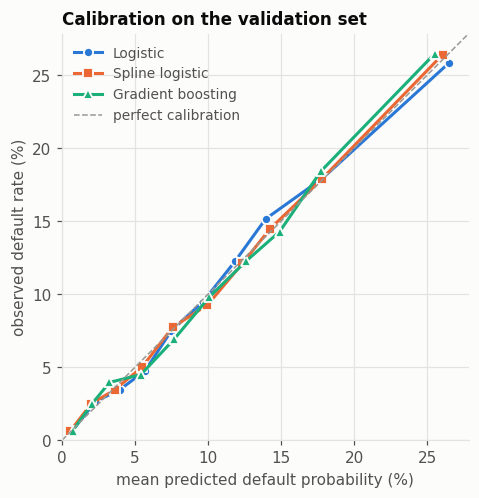

In [9]:
VAL[INFO] = pd.DataFrame(
    {name: predict_default(model, get_X(data, name, INFO, "validation"))
     for name, model in FITTED[INFO].items()},
    index=y_val.index)
val_table = ev.compare_models(y_val, VAL[INFO])[METRICS]

side_by_side = pd.concat({"out of fold (train)": oof_table, "validation": val_table.reindex(oof_table.index)},
                         axis=1)
display(side_by_side.xs("auc", axis=1, level=1, drop_level=False)
        .join(side_by_side.xs("logloss", axis=1, level=1, drop_level=False))
        .join(side_by_side.xs("calib_slope", axis=1, level=1, drop_level=False))
        .rename(index=mp.MODEL_LABELS).sort_index(axis=1, level=0, sort_remaining=False))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
mp.plot_reliability(y_val, VAL[INFO], ax, title="Calibration on the validation set")
plt.show()

### 1.6 Takeaways


* The three models are almost equally good: out-of-fold AUC 0.735-0.736, log-loss 0.2904-0.2909.
  The spline logistic is best on log-loss, gradient boosting a very close second.
* All three are well calibrated: calibration slopes 0.99-1.01, average prediction equal to the 9.95%
  default rate, and the deciles lie on the diagonal, including the low-risk end where the cheapest
  loans are priced.
* Validation confirms the out-of-fold picture: AUC 0.735-0.736, log-loss 0.2909-0.2915, calibration
  slopes 0.99-1.00. There is no sign of over-fitting.
* With our information set, about 10% of the log-loss of a naive "everyone defaults at 9.95%"
  prediction can be removed (log-loss skill 0.10). Most of that comes from income; our signal adds
  a clear but modest part (section 6.4).

---

## 2. `full` — full information: public variables + signals 1, 2 and 3


The **full-information model** uses all three private signals. No lender can build it at
application time (each lender only sees its own signal), but the past loans contain all three, so
we can estimate it. It is the benchmark for **how much we are missing** by seeing only `signal3`,
and the best available approximation of the true default probability. Part 5 compares it with our
predictions to understand the risk of the borrowers we win.

### 2.1 Features

In [10]:
INFO = "full"
for name in MODEL_FACTORIES:
    cols = feature_columns(name, INFO)
    print(f"{mp.MODEL_LABELS[name]:<18} ({len(cols):>2}) {', '.join(cols)}")

Logistic           (15) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_log1p_sq, income_zero, unemployed_x_income_zero, signal1, signal1_missing, signal2, signal2_missing, signal3, signal3_missing
Spline logistic    (14) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_zero, unemployed_x_income_zero, signal1, signal1_missing, signal2, signal2_missing, signal3, signal3_missing
Gradient boosting  (14) sex_F, married, employment_employed, employment_retired, employment_student, employment_unemployed, income, income_zero, signal1, signal1_missing, signal2, signal2_missing, signal3, signal3_missing


### 2.2 Training: out-of-fold predictions

Each model is trained 5 times, each time on 4 folds, and predicts the 5th. The table compares the
three models on the 80,000 out-of-fold predictions, best log-loss first.

In [11]:
OOF[INFO] = (oof_predict_all(data, folds, info_sets=[INFO])
             .rename(columns=lambda c: c.split("__")[1]))
oof_table = ev.compare_models(y_train, OOF[INFO])[METRICS]
oof_table.rename(index=mp.MODEL_LABELS)

,auc,logloss,logloss_skill,brier,calib_slope,calib_intercept,mean_pred,default_rate
Spline logistic,0.7594,0.2830,0.1263,0.0818,0.9927,-0.0133,0.0995,0.0995
Gradient boosting,0.7586,0.2835,0.1247,0.0819,1.0064,0.0132,0.0994,0.0995
Logistic,0.7582,0.2837,0.1241,0.0820,1.0054,0.0100,0.0995,0.0995


### 2.3 What each model has learned

All three models are refitted on the whole training set.

**Logistic regression coefficients.** Bars are standardized coefficients: the change in the
log-odds of default for a one-standard-deviation increase of the variable (positive = riskier).
`odds_ratio` is per one unit; for a 0/1 variable it is how the odds of default change when the
variable switches from 0 to 1. `income_log1p` and its square must be read together (see the
income curve below), not one by one.

,std_coef,raw_coef,odds_ratio
income_log1p,4.1755,1.1440,3.1392
income_zero,0.3981,1.0589,2.8833
sex_F,-0.0192,-0.0389,0.9619
unemployed_x_income_zero,-0.0342,-0.1348,0.8739
married,-0.0394,-0.0808,0.9224
employment_unemployed,-0.0655,-0.1867,0.8297
employment_student,-0.1225,-0.3332,0.7166
signal2_missing,-0.2211,-0.5431,0.5809
signal3_missing,-0.2425,-0.5941,0.5520
signal1_missing,-0.2484,-0.6114,0.5426


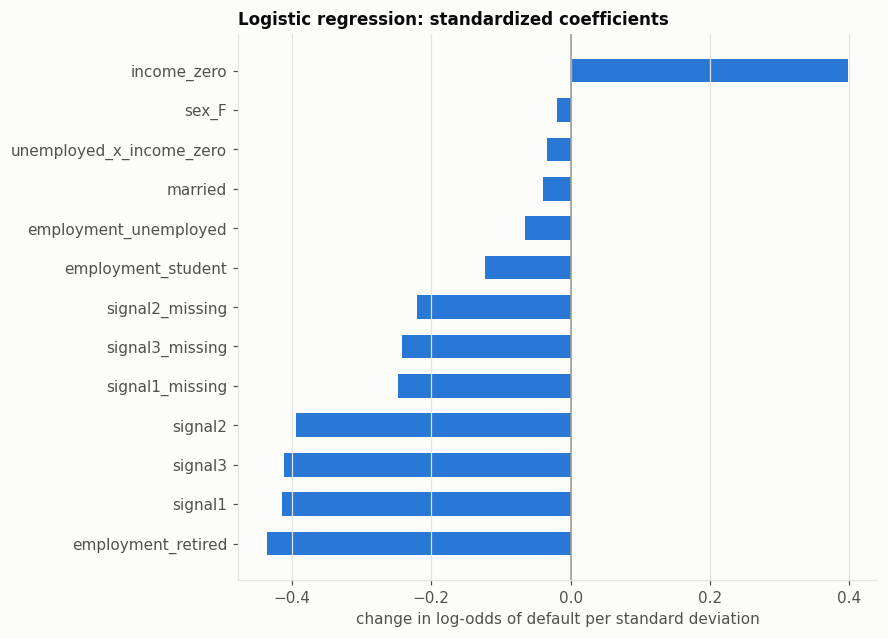

In [12]:
FITTED[INFO] = fit_models(data, INFO)
coefs = mp.logit_coefficients(FITTED[INFO]["logit"], feature_columns("logit", INFO))
display(coefs.sort_values("std_coef", ascending=False))
# income_log1p and its square are left out of the chart (see the income curve below).

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(coefs) + 1.2))
mp.plot_logit_coefficients(coefs, ax)
plt.show()

**Which variables each model relies on (permutation importance).** One variable at a time is
shuffled across loans, which destroys its information while keeping its distribution, and we
measure how much worse the log-loss gets. Related columns are shuffled together (e.g. income,
log income, income-zero flag and interaction; a signal and its missing flag). Measured on a
held-out fold the models were not trained on. This works the same way for all three models, so it
is the fair way to compare what they use.

,Logistic,Spline logistic,Gradient boosting
income,34.60,35.47,33.01
employment,5.06,4.24,3.00
signal1,3.13,3.13,2.75
signal3,3.03,3.07,2.95
signal2,2.57,2.62,2.52
married,0.05,0.05,-0.01
sex,-0.01,-0.00,0.04


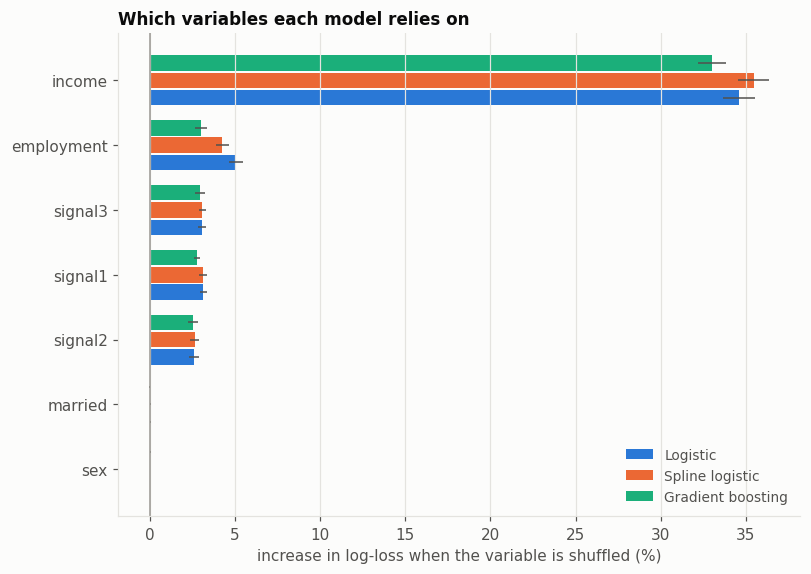

In [13]:
IMPORTANCE[INFO] = mp.holdout_importance(data, INFO, folds)
display(pd.concat({mp.MODEL_LABELS[m]: t["increase_pct"] for m, t in IMPORTANCE[INFO].items()},
                  axis=1).round(2))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(IMPORTANCE[INFO]["logit"]) + 1.5))
mp.plot_permutation_importance(IMPORTANCE[INFO], ax)
plt.show()

**How predicted risk moves with income and with the signal (partial dependence).** For 3,000
training loans, we set income (or the signal) to the same value for everyone and average the
predicted default probability; repeating over a grid of values traces the effect of that variable
with the others held at their observed values. The `none` marker is the prediction when the
lender received no signal. The dashed line is the average default rate.

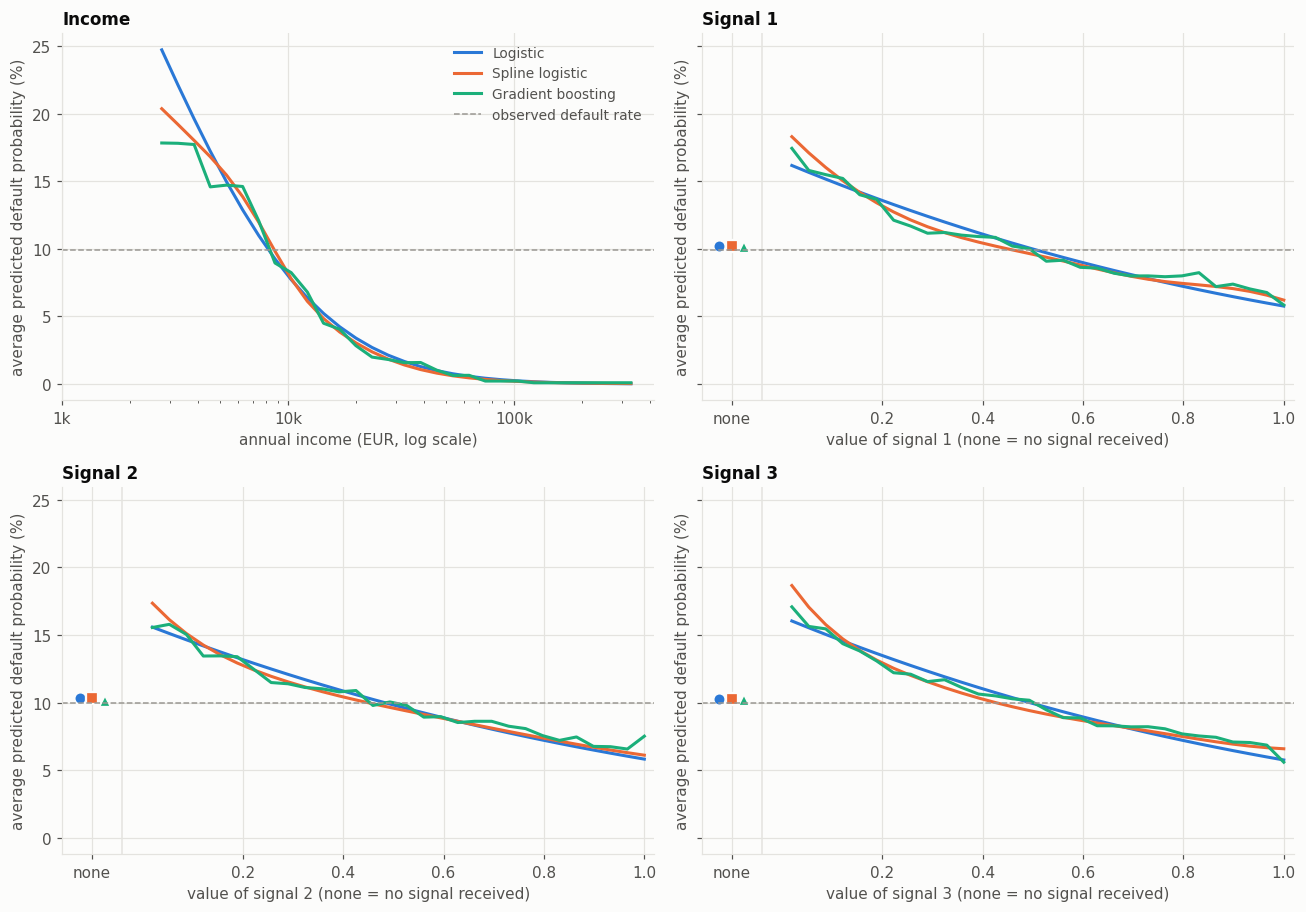

In [14]:
CURVES[INFO] = mp.dependence_curves(FITTED[INFO], data, INFO)
mp.plot_dependence_panels(CURVES[INFO], base_rate=y_train.mean())
plt.show()

**What the three models learned (full information set)**

* **Income still dominates** (33-35% log-loss increase when shuffled), with the same curve as in the
  own model.
* **The three signals are used in the same way and with similar weight.** Each has a standardized
  logistic coefficient between -0.39 and -0.41, an importance of 2.5-3.1%, and the same shape of
  partial dependence: from about 17% risk at low values to 6% at high values, with average risk when
  the signal is missing. This is what the EDA suggested: the three signals look like independent
  draws from the same mechanism, each capturing a different dimension of creditworthiness.
* **They are complementary, not redundant.** Each signal keeps almost the same importance as in its
  single-signal model (signal 3: 3.3-3.4% alone, 3.0-3.1% here). Because the signals are only weakly
  correlated, adding the other two brings genuinely new information. This is why the full model is
  clearly better (section 6.4).
* **Employment matters a little more here** (importance 3-5%). The retired coefficient becomes more
  negative (odds ratio 0.26 vs 0.42 in the own model), plausibly because retired applicants are often missing
  signals (36.5% for each signal in the EDA): with three missing flags the model can separate "retired" from "not scored".
* As before, sex and marital status contribute almost nothing.

### 2.4 Calibration

Left: loans are sorted into 10 equal-sized groups by predicted probability; each point compares
the group's average prediction with its observed default rate. On the dashed diagonal, a predicted
10% really means 10%. Right: how spread out the predictions are — a model that separates risk well
puts more loans far from the average.

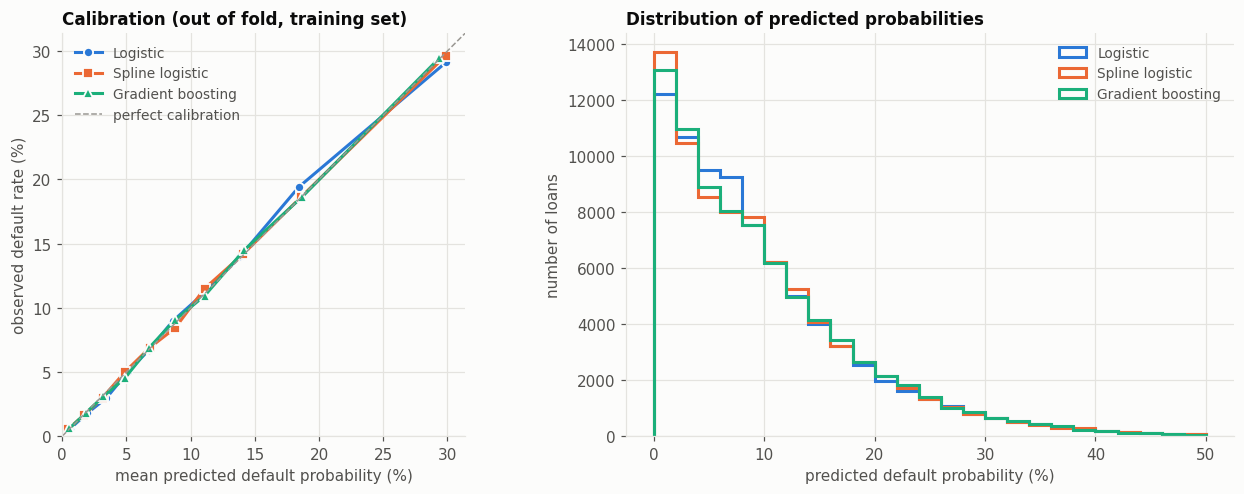

Predicted default probability, quantiles (out of fold):


,Logistic,Spline logistic,Gradient boosting
0.010000,0.08%,0.07%,0.13%
0.100000,1.27%,1.06%,1.24%
0.250000,3.44%,3.15%,3.21%
0.500000,7.63%,7.82%,7.77%
0.750000,13.82%,13.99%,14.14%
0.900000,21.80%,21.86%,21.96%
0.990000,40.01%,40.18%,38.55%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp.plot_reliability(y_train, OOF[INFO], axes[0],
                    title="Calibration (out of fold, training set)")
mp.plot_prediction_distribution(OOF[INFO], axes[1])
fig.tight_layout()
plt.show()

print("Predicted default probability, quantiles (out of fold):")
display(OOF[INFO].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
        .rename(columns=mp.MODEL_LABELS).style.format("{:.2%}"))

### 2.5 Validation

The models fitted on the whole training set predict the 20,000 validation loans, which no model
or choice has used so far.

out of fold (train)                     validation                    
                                  auc logloss calib_slope        auc logloss calib_slope
Spline logistic                0.7594  0.2830      0.9927     0.7598  0.2824      1.0123
Gradient boosting              0.7586  0.2835      1.0064     0.7587  0.2832      1.0051
Logistic                       0.7582  0.2837      1.0054     0.7586  0.2832      1.0226

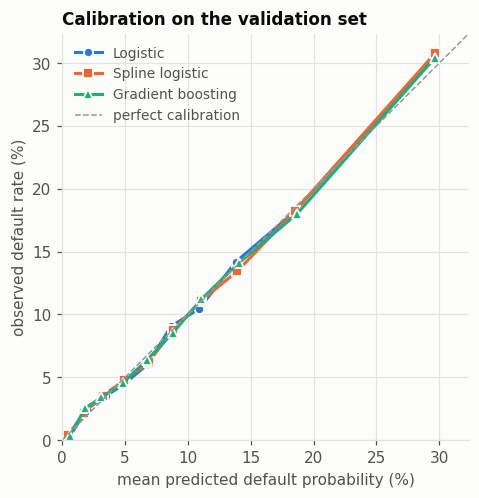

In [16]:
VAL[INFO] = pd.DataFrame(
    {name: predict_default(model, get_X(data, name, INFO, "validation"))
     for name, model in FITTED[INFO].items()},
    index=y_val.index)
val_table = ev.compare_models(y_val, VAL[INFO])[METRICS]

side_by_side = pd.concat({"out of fold (train)": oof_table, "validation": val_table.reindex(oof_table.index)},
                         axis=1)
display(side_by_side.xs("auc", axis=1, level=1, drop_level=False)
        .join(side_by_side.xs("logloss", axis=1, level=1, drop_level=False))
        .join(side_by_side.xs("calib_slope", axis=1, level=1, drop_level=False))
        .rename(index=mp.MODEL_LABELS).sort_index(axis=1, level=0, sort_remaining=False))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
mp.plot_reliability(y_val, VAL[INFO], ax, title="Calibration on the validation set")
plt.show()

### 2.6 Takeaways


* Best information set by a clear margin: out-of-fold AUC 0.758-0.759 and log-loss 0.2830-0.2837,
  against 0.736 and 0.2904 for our model. On validation, AUC 0.759-0.760, log-loss 0.2824-0.2832.
* The spline logistic is again the best model, the logistic regression and boosting are tied just
  behind.
* Calibration is good (slopes 1.01-1.02 on validation), so the full model's probabilities can serve as
  a reference "true" risk when we analyse adverse selection.

---

## 3. `lender1` — lender 1's view: public variables + signal 1


Our best guess of **lender 1's model**: public variables plus `signal1`. We do not know what lender 1
actually does; this is what a competent lender with its information would predict, trained on the
same past loans as us (all lenders have the same historical data). In Parts 4 to 7 these predictions
stand in for lender 1's view of each applicant, to simulate its offers.

### 3.1 Features

In [17]:
INFO = "lender1"
for name in MODEL_FACTORIES:
    cols = feature_columns(name, INFO)
    print(f"{mp.MODEL_LABELS[name]:<18} ({len(cols):>2}) {', '.join(cols)}")

Logistic           (11) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_log1p_sq, income_zero, unemployed_x_income_zero, signal1, signal1_missing
Spline logistic    (10) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_zero, unemployed_x_income_zero, signal1, signal1_missing
Gradient boosting  (10) sex_F, married, employment_employed, employment_retired, employment_student, employment_unemployed, income, income_zero, signal1, signal1_missing


### 3.2 Training: out-of-fold predictions

Each model is trained 5 times, each time on 4 folds, and predicts the 5th. The table compares the
three models on the 80,000 out-of-fold predictions, best log-loss first.

In [18]:
OOF[INFO] = (oof_predict_all(data, folds, info_sets=[INFO])
             .rename(columns=lambda c: c.split("__")[1]))
oof_table = ev.compare_models(y_train, OOF[INFO])[METRICS]
oof_table.rename(index=mp.MODEL_LABELS)

,auc,logloss,logloss_skill,brier,calib_slope,calib_intercept,mean_pred,default_rate
Spline logistic,0.7365,0.2904,0.1035,0.0837,0.9941,-0.0113,0.0995,0.0995
Logistic,0.7358,0.2909,0.1020,0.0839,1.0071,0.0135,0.0995,0.0995
Gradient boosting,0.7350,0.2910,0.1017,0.0838,0.9982,-0.0035,0.0995,0.0995


### 3.3 What each model has learned

All three models are refitted on the whole training set.

**Logistic regression coefficients.** Bars are standardized coefficients: the change in the
log-odds of default for a one-standard-deviation increase of the variable (positive = riskier).
`odds_ratio` is per one unit; for a 0/1 variable it is how the odds of default change when the
variable switches from 0 to 1. `income_log1p` and its square must be read together (see the
income curve below), not one by one.

,std_coef,raw_coef,odds_ratio
income_log1p,4.1406,1.1344,3.1094
income_zero,0.3947,1.0499,2.8573
sex_F,-0.0170,-0.0345,0.9661
unemployed_x_income_zero,-0.0312,-0.1229,0.8843
married,-0.0411,-0.0842,0.9193
employment_unemployed,-0.0670,-0.1911,0.8261
employment_student,-0.2442,-0.6641,0.5147
signal1_missing,-0.2617,-0.6443,0.5250
employment_retired,-0.2824,-0.8790,0.4152
signal1,-0.4343,-1.3346,0.2633


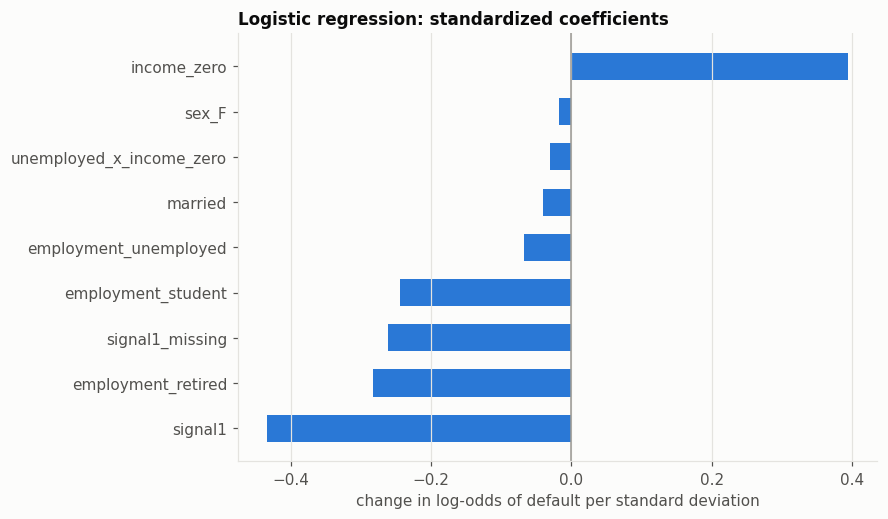

In [19]:
FITTED[INFO] = fit_models(data, INFO)
coefs = mp.logit_coefficients(FITTED[INFO]["logit"], feature_columns("logit", INFO))
display(coefs.sort_values("std_coef", ascending=False))
# income_log1p and its square are left out of the chart (see the income curve below).

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(coefs) + 1.2))
mp.plot_logit_coefficients(coefs, ax)
plt.show()

**Which variables each model relies on (permutation importance).** One variable at a time is
shuffled across loans, which destroys its information while keeping its distribution, and we
measure how much worse the log-loss gets. Related columns are shuffled together (e.g. income,
log income, income-zero flag and interaction; a signal and its missing flag). Measured on a
held-out fold the models were not trained on. This works the same way for all three models, so it
is the fair way to compare what they use.

,Logistic,Spline logistic,Gradient boosting
income,33.32,34.16,29.05
signal1,3.39,3.35,2.81
employment,3.35,2.71,1.49
married,0.06,0.05,-0.00
sex,-0.00,-0.01,0.05


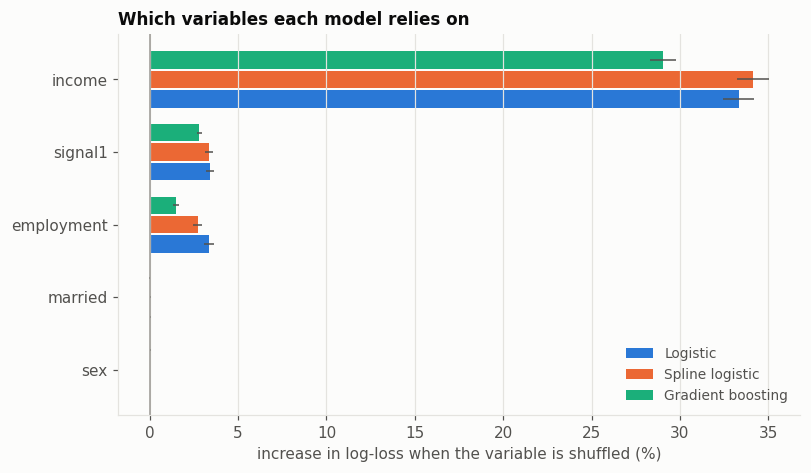

In [20]:
IMPORTANCE[INFO] = mp.holdout_importance(data, INFO, folds)
display(pd.concat({mp.MODEL_LABELS[m]: t["increase_pct"] for m, t in IMPORTANCE[INFO].items()},
                  axis=1).round(2))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(IMPORTANCE[INFO]["logit"]) + 1.5))
mp.plot_permutation_importance(IMPORTANCE[INFO], ax)
plt.show()

**How predicted risk moves with income and with the signal (partial dependence).** For 3,000
training loans, we set income (or the signal) to the same value for everyone and average the
predicted default probability; repeating over a grid of values traces the effect of that variable
with the others held at their observed values. The `none` marker is the prediction when the
lender received no signal. The dashed line is the average default rate.

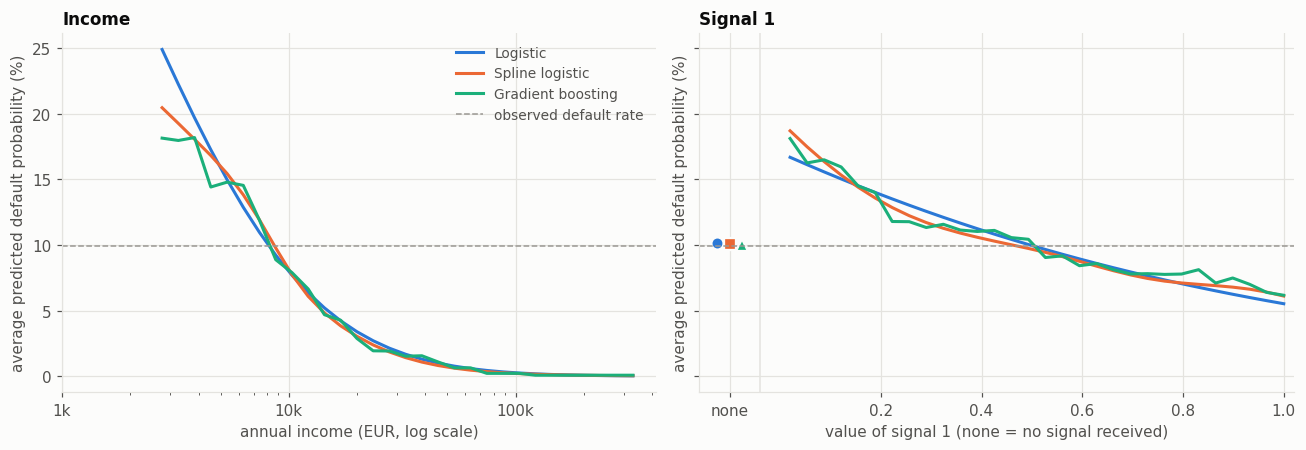

In [21]:
CURVES[INFO] = mp.dependence_curves(FITTED[INFO], data, INFO)
mp.plot_dependence_panels(CURVES[INFO], base_rate=y_train.mean())
plt.show()

**What the three models learned (lender 1's information set)**

* The picture is the same as for our own model, with `signal1` in place of `signal3`: income
  dominates (29-34%), then the signal (2.8-3.4%) and employment (1.5-3.4%), with sex and marital
  status negligible.
* `signal1` has the same effect as our signal: standardized coefficient -0.43 (ours: -0.43), risk
  falling from about 17% to 6% over its range, average risk when missing.
* So lender 1 is neither better nor worse informed than us: it sees a **different** but equally useful
  signal. What matters for competition is that the two signals disagree on individual applicants
  (section 6.6).

### 3.4 Calibration

Left: loans are sorted into 10 equal-sized groups by predicted probability; each point compares
the group's average prediction with its observed default rate. On the dashed diagonal, a predicted
10% really means 10%. Right: how spread out the predictions are — a model that separates risk well
puts more loans far from the average.

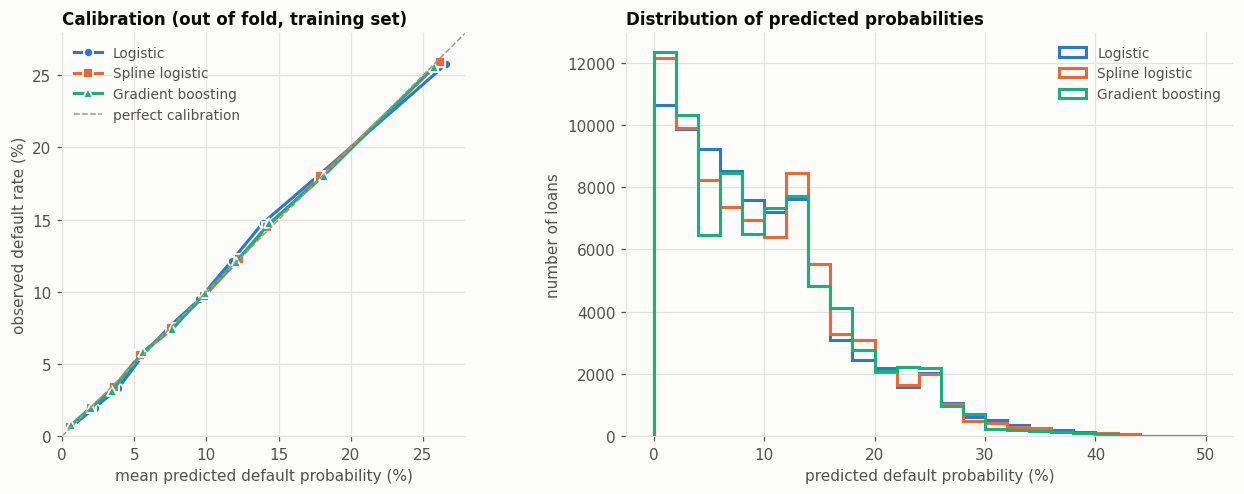

Predicted default probability, quantiles (out of fold):


,Logistic,Spline logistic,Gradient boosting
0.010000,0.10%,0.08%,0.11%
0.100000,1.47%,1.23%,1.44%
0.250000,3.90%,3.56%,3.44%
0.500000,8.44%,8.67%,8.71%
0.750000,13.80%,14.10%,14.36%
0.900000,20.81%,20.56%,20.99%
0.990000,33.44%,33.30%,30.94%


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp.plot_reliability(y_train, OOF[INFO], axes[0],
                    title="Calibration (out of fold, training set)")
mp.plot_prediction_distribution(OOF[INFO], axes[1])
fig.tight_layout()
plt.show()

print("Predicted default probability, quantiles (out of fold):")
display(OOF[INFO].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
        .rename(columns=mp.MODEL_LABELS).style.format("{:.2%}"))

### 3.5 Validation

The models fitted on the whole training set predict the 20,000 validation loans, which no model
or choice has used so far.

out of fold (train)                     validation                    
                                  auc logloss calib_slope        auc logloss calib_slope
Spline logistic                0.7365  0.2904      0.9941     0.7333  0.2912      0.9871
Logistic                       0.7358  0.2909      1.0071     0.7325  0.2916      1.0030
Gradient boosting              0.7350  0.2910      0.9982     0.7322  0.2917      0.9731

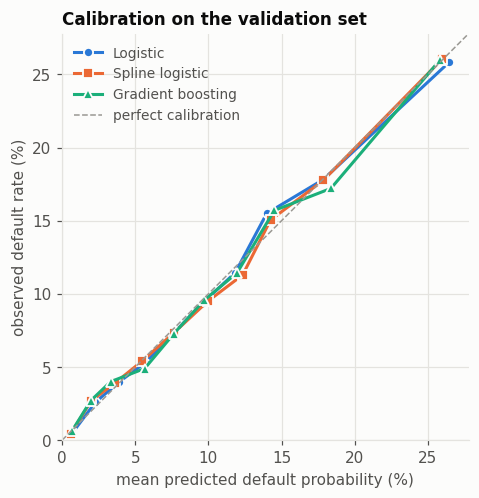

In [23]:
VAL[INFO] = pd.DataFrame(
    {name: predict_default(model, get_X(data, name, INFO, "validation"))
     for name, model in FITTED[INFO].items()},
    index=y_val.index)
val_table = ev.compare_models(y_val, VAL[INFO])[METRICS]

side_by_side = pd.concat({"out of fold (train)": oof_table, "validation": val_table.reindex(oof_table.index)},
                         axis=1)
display(side_by_side.xs("auc", axis=1, level=1, drop_level=False)
        .join(side_by_side.xs("logloss", axis=1, level=1, drop_level=False))
        .join(side_by_side.xs("calib_slope", axis=1, level=1, drop_level=False))
        .rename(index=mp.MODEL_LABELS).sort_index(axis=1, level=0, sort_remaining=False))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
mp.plot_reliability(y_val, VAL[INFO], ax, title="Calibration on the validation set")
plt.show()

### 3.6 Takeaways


* Out-of-fold AUC 0.735-0.737 and log-loss 0.2904-0.2910, the same level as our model; the spline
  logistic is again best.
* On validation, the lender 1 models score slightly lower (AUC 0.732-0.733) than out of fold. The
  difference is within the noise of a 20,000-loan sample (see the confidence intervals in 6.4).
* Calibration is good (slopes 0.97-1.00 on validation).

---

## 4. `lender2` — lender 2's view: public variables + signal 2


Our best guess of **lender 2's model**: public variables plus `signal2`, built in the same way and
for the same purpose as the lender 1 model.

### 4.1 Features

In [24]:
INFO = "lender2"
for name in MODEL_FACTORIES:
    cols = feature_columns(name, INFO)
    print(f"{mp.MODEL_LABELS[name]:<18} ({len(cols):>2}) {', '.join(cols)}")

Logistic           (11) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_log1p_sq, income_zero, unemployed_x_income_zero, signal2, signal2_missing
Spline logistic    (10) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_zero, unemployed_x_income_zero, signal2, signal2_missing
Gradient boosting  (10) sex_F, married, employment_employed, employment_retired, employment_student, employment_unemployed, income, income_zero, signal2, signal2_missing


### 4.2 Training: out-of-fold predictions

Each model is trained 5 times, each time on 4 folds, and predicts the 5th. The table compares the
three models on the 80,000 out-of-fold predictions, best log-loss first.

In [25]:
OOF[INFO] = (oof_predict_all(data, folds, info_sets=[INFO])
             .rename(columns=lambda c: c.split("__")[1]))
oof_table = ev.compare_models(y_train, OOF[INFO])[METRICS]
oof_table.rename(index=mp.MODEL_LABELS)

,auc,logloss,logloss_skill,brier,calib_slope,calib_intercept,mean_pred,default_rate
Spline logistic,0.7341,0.2908,0.1022,0.0839,0.9942,-0.0109,0.0995,0.0995
Gradient boosting,0.7338,0.2911,0.1015,0.0839,1.0041,0.0077,0.0995,0.0995
Logistic,0.7338,0.2913,0.1008,0.0840,1.0075,0.0144,0.0995,0.0995


### 4.3 What each model has learned

All three models are refitted on the whole training set.

**Logistic regression coefficients.** Bars are standardized coefficients: the change in the
log-odds of default for a one-standard-deviation increase of the variable (positive = riskier).
`odds_ratio` is per one unit; for a 0/1 variable it is how the odds of default change when the
variable switches from 0 to 1. `income_log1p` and its square must be read together (see the
income curve below), not one by one.

,std_coef,raw_coef,odds_ratio
income_log1p,4.1540,1.1381,3.1208
income_zero,0.3977,1.0579,2.8803
sex_F,-0.0191,-0.0387,0.9621
unemployed_x_income_zero,-0.0290,-0.1144,0.8919
married,-0.0374,-0.0767,0.9262
employment_unemployed,-0.0719,-0.2048,0.8148
signal2_missing,-0.2348,-0.5768,0.5617
employment_student,-0.2474,-0.6727,0.5103
employment_retired,-0.2809,-0.8743,0.4171
signal2,-0.4137,-1.2726,0.2801


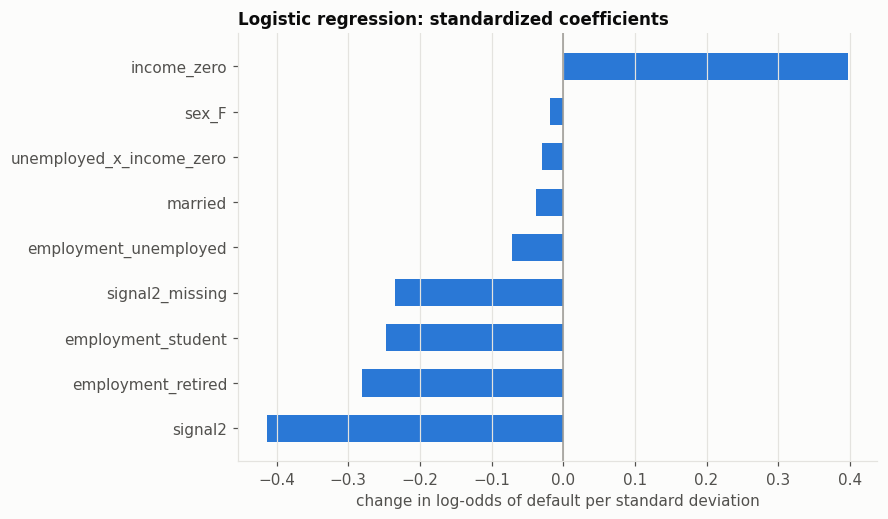

In [26]:
FITTED[INFO] = fit_models(data, INFO)
coefs = mp.logit_coefficients(FITTED[INFO]["logit"], feature_columns("logit", INFO))
display(coefs.sort_values("std_coef", ascending=False))
# income_log1p and its square are left out of the chart (see the income curve below).

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(coefs) + 1.2))
mp.plot_logit_coefficients(coefs, ax)
plt.show()

**Which variables each model relies on (permutation importance).** One variable at a time is
shuffled across loans, which destroys its information while keeping its distribution, and we
measure how much worse the log-loss gets. Related columns are shuffled together (e.g. income,
log income, income-zero flag and interaction; a signal and its missing flag). Measured on a
held-out fold the models were not trained on. This works the same way for all three models, so it
is the fair way to compare what they use.

,Logistic,Spline logistic,Gradient boosting
income,33.40,34.24,28.95
employment,3.37,2.74,1.67
signal2,2.81,2.81,2.49
married,0.04,0.04,0.00
sex,-0.01,-0.01,0.03


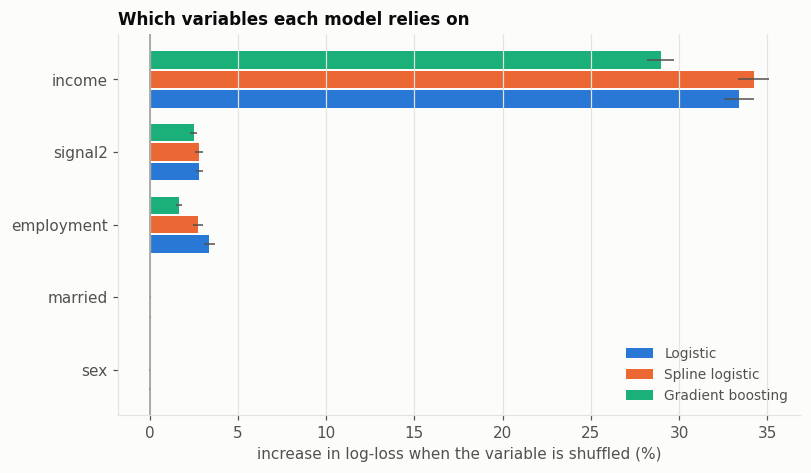

In [27]:
IMPORTANCE[INFO] = mp.holdout_importance(data, INFO, folds)
display(pd.concat({mp.MODEL_LABELS[m]: t["increase_pct"] for m, t in IMPORTANCE[INFO].items()},
                  axis=1).round(2))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(IMPORTANCE[INFO]["logit"]) + 1.5))
mp.plot_permutation_importance(IMPORTANCE[INFO], ax)
plt.show()

**How predicted risk moves with income and with the signal (partial dependence).** For 3,000
training loans, we set income (or the signal) to the same value for everyone and average the
predicted default probability; repeating over a grid of values traces the effect of that variable
with the others held at their observed values. The `none` marker is the prediction when the
lender received no signal. The dashed line is the average default rate.

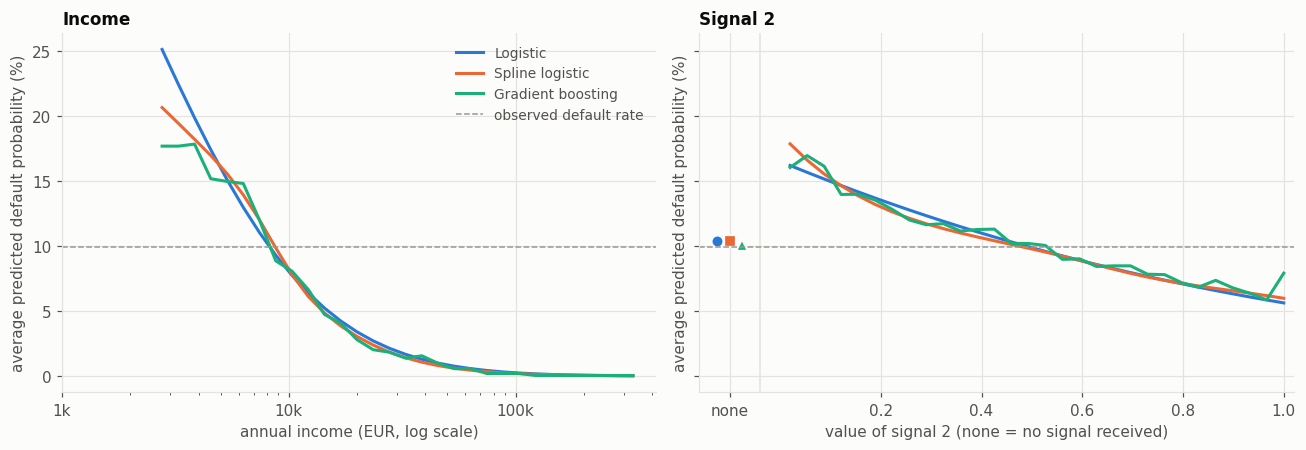

In [28]:
CURVES[INFO] = mp.dependence_curves(FITTED[INFO], data, INFO)
mp.plot_dependence_panels(CURVES[INFO], base_rate=y_train.mean())
plt.show()

**What the three models learned (lender 2's information set)**

* Same structure again: income first (29-34%), then employment (1.7-3.4%) and `signal2`
  (2.5-2.8%), sex and marital status negligible.
* `signal2` has a slightly weaker effect than the other two signals (standardized coefficient -0.41,
  importance about 2.8% vs 3.4%), consistent with its slightly lower stand-alone AUC in the EDA
  (0.572 vs 0.576). Its shape is the same: lower risk for higher values, average risk when missing.

### 4.4 Calibration

Left: loans are sorted into 10 equal-sized groups by predicted probability; each point compares
the group's average prediction with its observed default rate. On the dashed diagonal, a predicted
10% really means 10%. Right: how spread out the predictions are — a model that separates risk well
puts more loans far from the average.

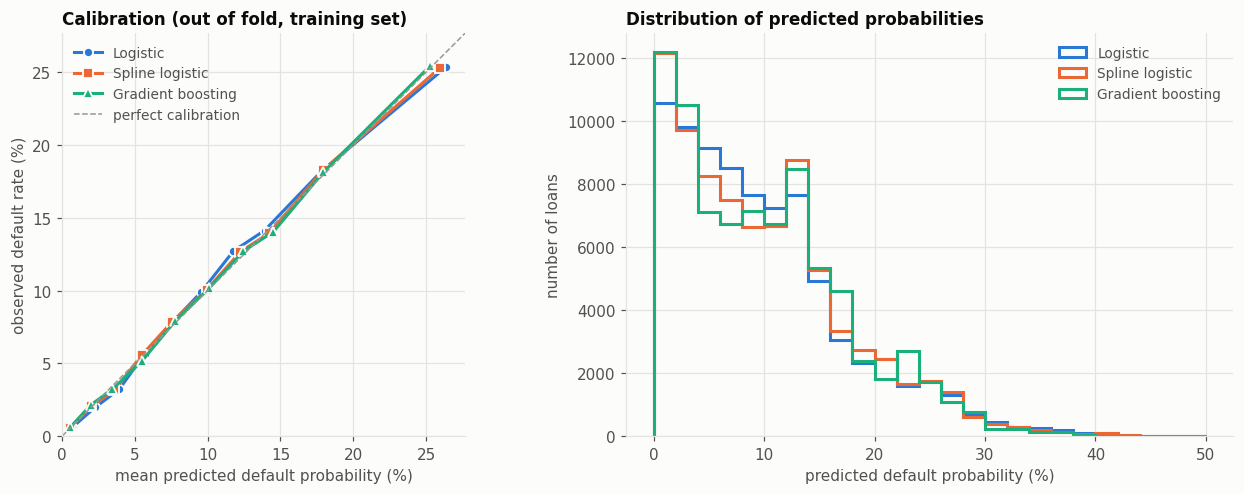

Predicted default probability, quantiles (out of fold):


,Logistic,Spline logistic,Gradient boosting
0.010000,0.10%,0.09%,0.10%
0.100000,1.50%,1.24%,1.21%
0.250000,3.92%,3.59%,3.44%
0.500000,8.48%,8.70%,8.92%
0.750000,13.83%,14.10%,14.44%
0.900000,20.84%,20.73%,21.16%
0.990000,33.07%,32.10%,29.86%


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp.plot_reliability(y_train, OOF[INFO], axes[0],
                    title="Calibration (out of fold, training set)")
mp.plot_prediction_distribution(OOF[INFO], axes[1])
fig.tight_layout()
plt.show()

print("Predicted default probability, quantiles (out of fold):")
display(OOF[INFO].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
        .rename(columns=mp.MODEL_LABELS).style.format("{:.2%}"))

### 4.5 Validation

The models fitted on the whole training set predict the 20,000 validation loans, which no model
or choice has used so far.

out of fold (train)                     validation                    
                                  auc logloss calib_slope        auc logloss calib_slope
Spline logistic                0.7341  0.2908      0.9942     0.7329  0.2915      0.9868
Gradient boosting              0.7338  0.2911      1.0041     0.7314  0.2922      0.9660
Logistic                       0.7338  0.2913      1.0075     0.7321  0.2919      1.0041

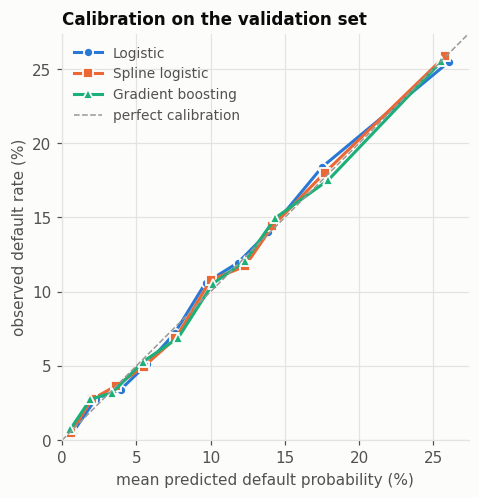

In [30]:
VAL[INFO] = pd.DataFrame(
    {name: predict_default(model, get_X(data, name, INFO, "validation"))
     for name, model in FITTED[INFO].items()},
    index=y_val.index)
val_table = ev.compare_models(y_val, VAL[INFO])[METRICS]

side_by_side = pd.concat({"out of fold (train)": oof_table, "validation": val_table.reindex(oof_table.index)},
                         axis=1)
display(side_by_side.xs("auc", axis=1, level=1, drop_level=False)
        .join(side_by_side.xs("logloss", axis=1, level=1, drop_level=False))
        .join(side_by_side.xs("calib_slope", axis=1, level=1, drop_level=False))
        .rename(index=mp.MODEL_LABELS).sort_index(axis=1, level=0, sort_remaining=False))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
mp.plot_reliability(y_val, VAL[INFO], ax, title="Calibration on the validation set")
plt.show()

### 4.6 Takeaways


* Out-of-fold AUC 0.734 and log-loss 0.2908-0.2913, marginally below our model and lender 1's; the
  spline logistic is best.
* Validation: AUC 0.731-0.733, log-loss 0.2915-0.2922, calibration slopes 0.97-1.00. Boosting is the
  least well calibrated of the three here (slope 0.97, predictions slightly too spread out).

---

## 5. `public` — public variables only


**Public variables only** (sex, employment, marital status, income): what any lender could predict
without a private signal. Not used for pricing; it is the baseline that measures how much a private
signal is worth.

### 5.1 Features

In [31]:
INFO = "public"
for name in MODEL_FACTORIES:
    cols = feature_columns(name, INFO)
    print(f"{mp.MODEL_LABELS[name]:<18} ({len(cols):>2}) {', '.join(cols)}")

Logistic           ( 9) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_log1p_sq, income_zero, unemployed_x_income_zero
Spline logistic    ( 8) sex_F, married, employment_retired, employment_student, employment_unemployed, income_log1p, income_zero, unemployed_x_income_zero
Gradient boosting  ( 8) sex_F, married, employment_employed, employment_retired, employment_student, employment_unemployed, income, income_zero


### 5.2 Training: out-of-fold predictions

Each model is trained 5 times, each time on 4 folds, and predicts the 5th. The table compares the
three models on the 80,000 out-of-fold predictions, best log-loss first.

In [32]:
OOF[INFO] = (oof_predict_all(data, folds, info_sets=[INFO])
             .rename(columns=lambda c: c.split("__")[1]))
oof_table = ev.compare_models(y_train, OOF[INFO])[METRICS]
oof_table.rename(index=mp.MODEL_LABELS)

,auc,logloss,logloss_skill,brier,calib_slope,calib_intercept,mean_pred,default_rate
Spline logistic,0.7189,0.2946,0.0905,0.0848,0.9955,-0.0086,0.0995,0.0995
Gradient boosting,0.7174,0.2949,0.0895,0.0848,1.0091,0.0169,0.0995,0.0995
Logistic,0.7188,0.2950,0.0892,0.0849,1.0093,0.0179,0.0995,0.0995


### 5.3 What each model has learned

All three models are refitted on the whole training set.

**Logistic regression coefficients.** Bars are standardized coefficients: the change in the
log-odds of default for a one-standard-deviation increase of the variable (positive = riskier).
`odds_ratio` is per one unit; for a 0/1 variable it is how the odds of default change when the
variable switches from 0 to 1. `income_log1p` and its square must be read together (see the
income curve below), not one by one.

,std_coef,raw_coef,odds_ratio
income_log1p,4.1389,1.1339,3.1079
income_zero,0.4000,1.0640,2.8978
sex_F,-0.0166,-0.0336,0.9669
unemployed_x_income_zero,-0.0289,-0.1140,0.8923
married,-0.0385,-0.0789,0.9241
employment_unemployed,-0.0708,-0.2017,0.8173
employment_retired,-0.1983,-0.6174,0.5394
employment_student,-0.3103,-0.8437,0.4301
income_log1p_sq,-4.8004,-0.1280,0.8798


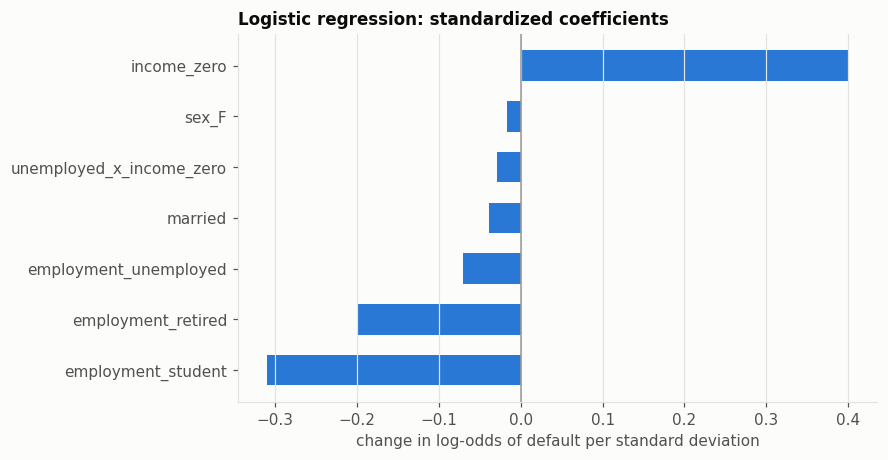

In [33]:
FITTED[INFO] = fit_models(data, INFO)
coefs = mp.logit_coefficients(FITTED[INFO]["logit"], feature_columns("logit", INFO))
display(coefs.sort_values("std_coef", ascending=False))
# income_log1p and its square are left out of the chart (see the income curve below).

fig, ax = plt.subplots(figsize=(7.5, 0.35 * len(coefs) + 1.2))
mp.plot_logit_coefficients(coefs, ax)
plt.show()

**Which variables each model relies on (permutation importance).** One variable at a time is
shuffled across loans, which destroys its information while keeping its distribution, and we
measure how much worse the log-loss gets. Related columns are shuffled together (e.g. income,
log income, income-zero flag and interaction; a signal and its missing flag). Measured on a
held-out fold the models were not trained on. This works the same way for all three models, so it
is the fair way to compare what they use.

,Logistic,Spline logistic,Gradient boosting
income,32.69,33.45,27.83
employment,3.66,3.03,1.69
married,0.05,0.05,0.00
sex,-0.01,-0.01,0.05


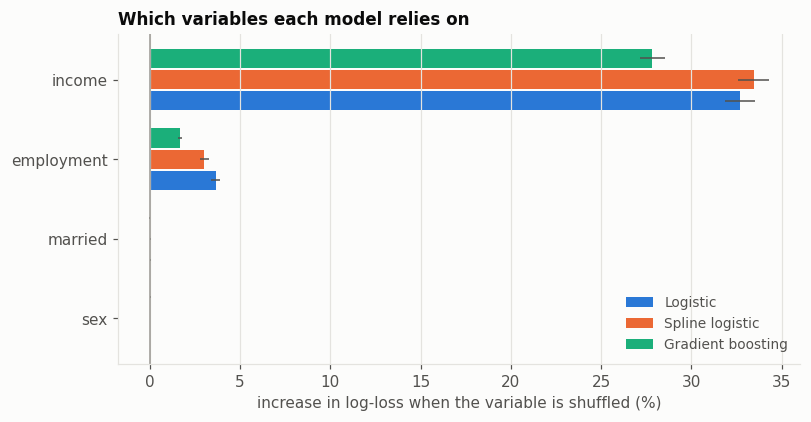

In [34]:
IMPORTANCE[INFO] = mp.holdout_importance(data, INFO, folds)
display(pd.concat({mp.MODEL_LABELS[m]: t["increase_pct"] for m, t in IMPORTANCE[INFO].items()},
                  axis=1).round(2))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(IMPORTANCE[INFO]["logit"]) + 1.5))
mp.plot_permutation_importance(IMPORTANCE[INFO], ax)
plt.show()

**How predicted risk moves with income and with the signal (partial dependence).** For 3,000
training loans, we set income (or the signal) to the same value for everyone and average the
predicted default probability; repeating over a grid of values traces the effect of that variable
with the others held at their observed values. The `none` marker is the prediction when the
lender received no signal. The dashed line is the average default rate.

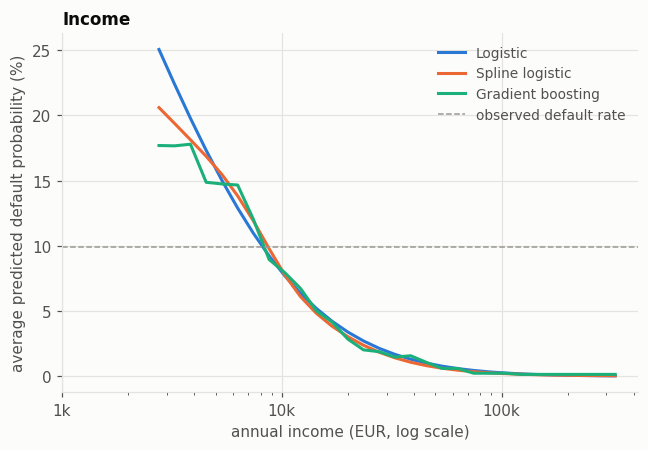

In [35]:
CURVES[INFO] = mp.dependence_curves(FITTED[INFO], data, INFO)
mp.plot_dependence_panels(CURVES[INFO], base_rate=y_train.mean())
plt.show()

**What the three models learned (public variables only)**

* Without a signal, income carries almost all the information (28-33%), employment adds 1.7-3.7%,
  sex and marital status nothing.
* The income curves are the same as in the other information sets: the signals do not change how
  income is used, they add information on top of it. This matches the EDA finding that the signals
  are only weakly related to the public variables.

### 5.4 Calibration

Left: loans are sorted into 10 equal-sized groups by predicted probability; each point compares
the group's average prediction with its observed default rate. On the dashed diagonal, a predicted
10% really means 10%. Right: how spread out the predictions are — a model that separates risk well
puts more loans far from the average.

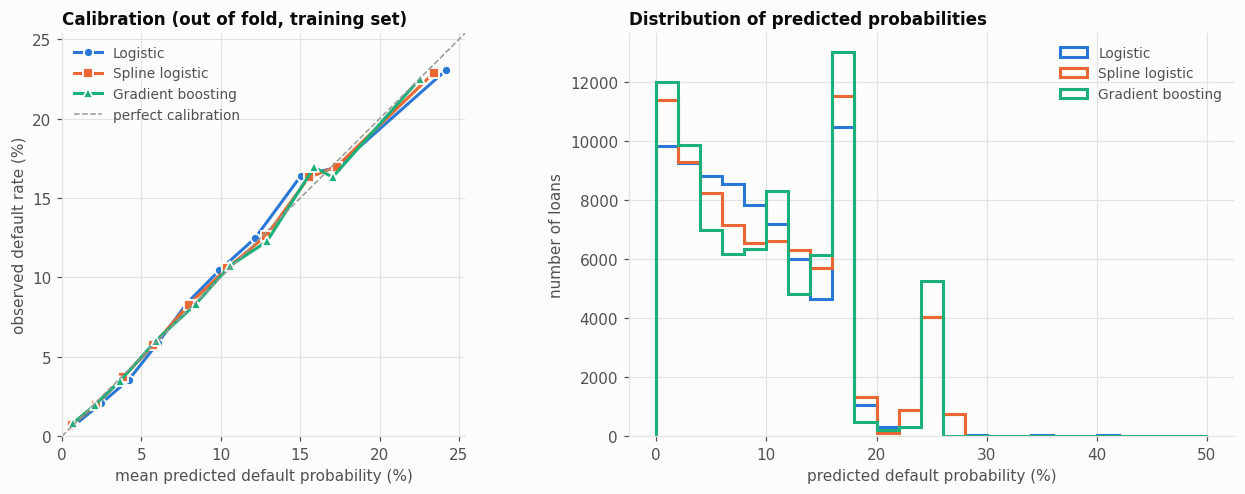

Predicted default probability, quantiles (out of fold):


,Logistic,Spline logistic,Gradient boosting
0.010000,0.10%,0.09%,0.24%
0.100000,1.62%,1.33%,1.55%
0.250000,4.19%,3.83%,3.54%
0.500000,8.88%,9.19%,9.79%
0.750000,14.99%,15.52%,15.78%
0.900000,17.71%,17.68%,17.41%
0.990000,26.49%,25.94%,25.28%


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
mp.plot_reliability(y_train, OOF[INFO], axes[0],
                    title="Calibration (out of fold, training set)")
mp.plot_prediction_distribution(OOF[INFO], axes[1])
fig.tight_layout()
plt.show()

print("Predicted default probability, quantiles (out of fold):")
display(OOF[INFO].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
        .rename(columns=mp.MODEL_LABELS).style.format("{:.2%}"))

### 5.5 Validation

The models fitted on the whole training set predict the 20,000 validation loans, which no model
or choice has used so far.

out of fold (train)                     validation                    
                                  auc logloss calib_slope        auc logloss calib_slope
Spline logistic                0.7189  0.2946      0.9955     0.7152  0.2961      0.9650
Gradient boosting              0.7174  0.2949      1.0091     0.7144  0.2963      0.9630
Logistic                       0.7188  0.2950      1.0093     0.7145  0.2964      0.9843

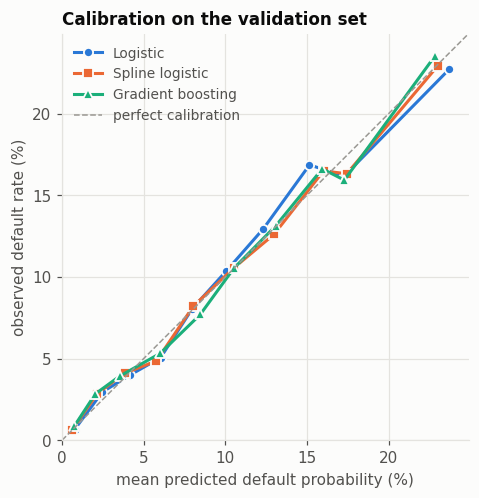

In [37]:
VAL[INFO] = pd.DataFrame(
    {name: predict_default(model, get_X(data, name, INFO, "validation"))
     for name, model in FITTED[INFO].items()},
    index=y_val.index)
val_table = ev.compare_models(y_val, VAL[INFO])[METRICS]

side_by_side = pd.concat({"out of fold (train)": oof_table, "validation": val_table.reindex(oof_table.index)},
                         axis=1)
display(side_by_side.xs("auc", axis=1, level=1, drop_level=False)
        .join(side_by_side.xs("logloss", axis=1, level=1, drop_level=False))
        .join(side_by_side.xs("calib_slope", axis=1, level=1, drop_level=False))
        .rename(index=mp.MODEL_LABELS).sort_index(axis=1, level=0, sort_remaining=False))

fig, ax = plt.subplots(figsize=(5.5, 4.8))
mp.plot_reliability(y_val, VAL[INFO], ax, title="Calibration on the validation set")
plt.show()

### 5.6 Takeaways


* Out-of-fold AUC 0.717-0.719 and log-loss 0.2946-0.2950; validation AUC 0.714-0.715.
* So the public variables alone already achieve most of what is achievable: AUC 0.72, against 0.74
  with one signal and 0.76 with all three.
* Validation calibration slopes are slightly below 1 (0.96-0.98): on these 20,000 loans the public
  models are a little over-confident, which the models with a signal are not.

---

## 6. Comparisons and conclusions


This section puts the 15 models side by side, selects one model per information set, measures the
value of each information set, checks whether recalibration helps, looks at how differently the
lenders see the same applicants, and produces the deliverables.

### 6.1 All results

Out-of-fold metrics on the training set (used for selection) next to validation metrics.

In [38]:
oof_all = pd.concat([OOF[i].add_prefix(f"{i}__") for i in INFORMATION_SETS], axis=1)
val_all = pd.concat([VAL[i].add_prefix(f"{i}__") for i in INFORMATION_SETS], axis=1)

table_oof = ev.metrics_by_information_set(y_train, oof_all)
table_val = ev.metrics_by_information_set(y_val, val_all).reindex(table_oof.index)

summary = pd.concat({"out of fold (train)": table_oof[["auc", "logloss", "logloss_skill", "calib_slope"]],
                     "validation": table_val[["auc", "logloss", "logloss_skill", "calib_slope"]]},
                    axis=1)
summary

out of fold (train)                                   validation                                  
                                auc logloss logloss_skill calib_slope        auc logloss logloss_skill calib_slope
info_set model                                                                                                    
own      spline              0.7357  0.2904        0.1036      0.9950     0.7360  0.2909        0.1018      0.9909
         gb                  0.7355  0.2906        0.1028      1.0122     0.7364  0.2909        0.1018      1.0002
         logit               0.7351  0.2909        0.1019      1.0077     0.7346  0.2915        0.1001      1.0027
full     spline              0.7594  0.2830        0.1263      0.9927     0.7598  0.2824        0.1281      1.0123
         gb                  0.7586  0.2835        0.1247      1.0064     0.7587  0.2832        0.1257      1.0051
         logit               0.7582  0.2837        0.1241      1.0054     0.7586  0.2832        0.1255      1.0226
lender1  spline              0.7365  0.2904        0.1035      0.9941     0.7333  0.2912        0.1009      0.9871
         logit               0.7358  0.2909        0.1020      1.0071     0.7325  0.2916        0.0996      1.0030
         gb                  0.7350  0.2910        0.1017      0.9982     0.7322  0.2917        0.0993      0.9731
lender2  spline              0.7341  0.2908        0.1022      0.9942     0.7329  0.2915        0.0998      0.9868
         gb                  0.7338  0.2911        0.1015      1.0041     0.7314  0.2922        0.0977      0.9660
         logit               0.7338  0.2913        0.1008      1.0075     0.7321  0.2919        0.0987      1.0041
public   spline              0.7189  0.2946        0.0905      0.9955     0.7152  0.2961        0.0858      0.9650
         gb                  0.7174  0.2949        0.0895      1.0091     0.7144  0.2963        0.0851      0.9630
         logit               0.7188  0.2950        0.0892      1.0093     0.7145  0.2964        0.0849      0.9843

### 6.2 Comparing the three models

Log-loss skill (share of log-loss removed relative to predicting the average default rate) by
information set and model, out of fold. Then, on the validation set, a paired bootstrap of the
difference between the best model of each information set and the two others: the same 1,000
resampled sets of loans score both models, so the interval measures whether the gap is real.

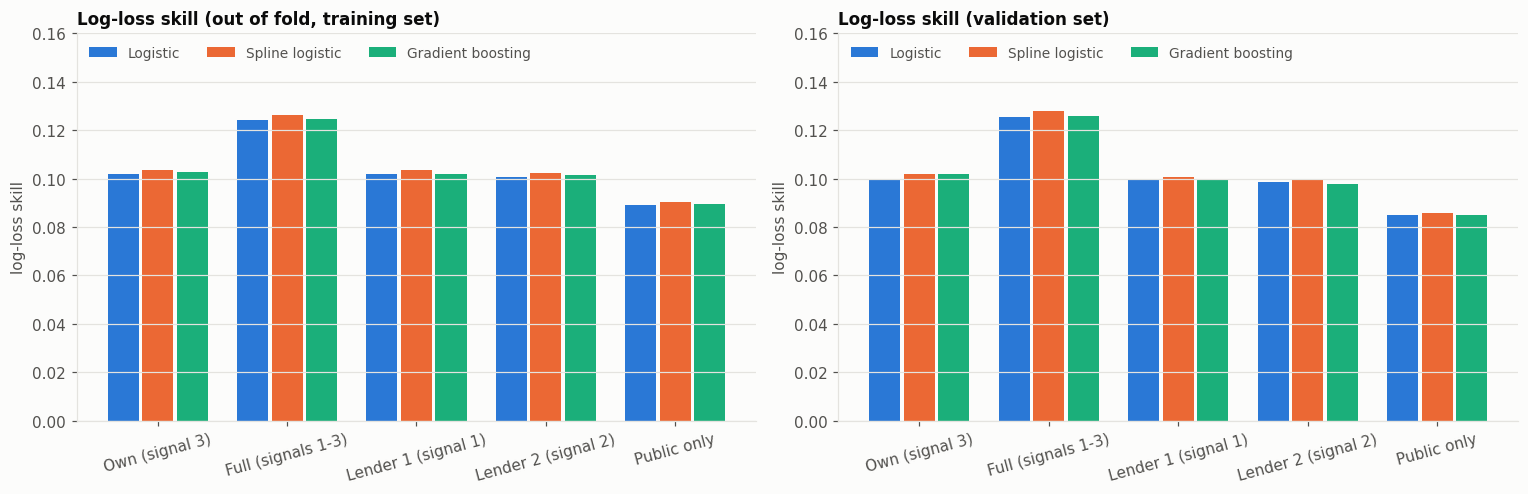

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
mp.plot_metric_by_info_set(table_oof, "logloss_skill", axes[0],
                           "Log-loss skill (out of fold, training set)", "log-loss skill")
mp.plot_metric_by_info_set(table_val, "logloss_skill", axes[1],
                           "Log-loss skill (validation set)", "log-loss skill")
top = max(table_oof["logloss_skill"].max(), table_val["logloss_skill"].max()) * 1.25
for ax in axes:
    ax.set_ylim(0, top)
fig.tight_layout()
plt.show()

In [40]:
rows = []
for info in INFORMATION_SETS:
    best = table_oof.loc[info, "logloss"].idxmin()
    for other in MODEL_FACTORIES:
        if other == best:
            continue
        a, b = VAL[info][best], VAL[info][other]
        ll = ev.bootstrap_diff_ci(y_val, a, b, metric=ev.logloss)
        au = ev.bootstrap_diff_ci(y_val, a, b, metric=ev.auc)
        rows.append({"info_set": info, "best (OOF)": mp.MODEL_LABELS[best],
                     "vs": mp.MODEL_LABELS[other],
                     "logloss diff": ll["estimate"], "logloss 95% CI": f"[{ll['lower']:+.4f}, {ll['upper']:+.4f}]",
                     "AUC diff": au["estimate"], "AUC 95% CI": f"[{au['lower']:+.4f}, {au['upper']:+.4f}]"})
model_tests = pd.DataFrame(rows).set_index(["info_set", "best (OOF)", "vs"])
model_tests

logloss diff      logloss 95% CI  AUC diff          AUC 95% CI
info_set best (OOF)      vs                                                                               
own      Spline logistic Logistic            -5.6557e-04  [-0.0010, -0.0001]    0.0014  [+0.0001, +0.0026]
                         Gradient boosting   -2.4136e-06  [-0.0007, +0.0008]   -0.0004  [-0.0028, +0.0021]
full     Spline logistic Logistic            -8.3019e-04  [-0.0014, -0.0002]    0.0012  [-0.0004, +0.0027]
                         Gradient boosting   -7.6921e-04  [-0.0016, +0.0001]    0.0011  [-0.0015, +0.0038]
lender1  Spline logistic Logistic            -4.1565e-04  [-0.0008, +0.0000]    0.0008  [-0.0005, +0.0020]
                         Gradient boosting   -5.0434e-04  [-0.0012, +0.0001]    0.0011  [-0.0011, +0.0034]
lender2  Spline logistic Logistic            -3.7027e-04  [-0.0008, +0.0001]    0.0008  [-0.0004, +0.0019]
                         Gradient boosting   -6.8579e-04  [-0.0014, -0.0000]    0.0014  [-0.0011, +0.0039]
public   Spline logistic Logistic            -2.9519e-04  [-0.0007, +0.0001]    0.0008  [-0.0003, +0.0019]
                         Gradient boosting   -2.4574e-04  [-0.0008, +0.0003]    0.0009  [-0.0015, +0.0033]

**The choice of model matters very little.** Within each information set, the three models are
within 0.001 of log-loss of each other (about 0.3%) and within 0.002 of AUC.

* The **spline logistic** has the lowest out-of-fold log-loss in all five information sets.
* On validation it beats the plain **logistic regression** or our model and the full model, and is ahead but not significantly for the others.
* Against **gradient boosting** the differences are not significant on validation (all intervals
  include 0, except lender 2, where boosting is also less well calibrated). For our own model the two
  are tied (log-loss difference -0.000002).

So the data are close to additive in the log-odds, and the only thing worth capturing beyond a
logistic regression is a little curvature in income and in the signals.

### 6.3 Model selection

Rule, fixed before looking at validation: for each information set, the model with the **lowest
out-of-fold log-loss**.

In [41]:
SELECTED = {info: table_oof.loc[info, "logloss"].idxmin() for info in INFORMATION_SETS}
selected_table = pd.DataFrame(
    {"selected model": {i: mp.MODEL_LABELS[m] for i, m in SELECTED.items()},
     "OOF logloss": {i: table_oof.loc[(i, m), "logloss"] for i, m in SELECTED.items()},
     "validation logloss": {i: table_val.loc[(i, m), "logloss"] for i, m in SELECTED.items()},
     "validation AUC": {i: table_val.loc[(i, m), "auc"] for i, m in SELECTED.items()},
     "validation calib slope": {i: table_val.loc[(i, m), "calib_slope"] for i, m in SELECTED.items()}})
selected_table

,selected model,OOF logloss,validation logloss,validation AUC,validation calib slope
own,Spline logistic,0.2904,0.2909,0.7360,0.9909
full,Spline logistic,0.2830,0.2824,0.7598,1.0123
lender1,Spline logistic,0.2904,0.2912,0.7333,0.9871
lender2,Spline logistic,0.2908,0.2915,0.7329,0.9868
public,Spline logistic,0.2946,0.2961,0.7152,0.9650


**The spline logistic regression is selected for all five information sets.** The validation set
confirms the choice: its validation log-loss is the best or tied-best in every information set, and
its calibration slope is between 0.96 and 1.01.

Using the same model family everywhere has a second advantage: when we compare our predictions with
the full-information and competitor predictions (Parts 4-7), the differences come from the
information, not from different modelling choices.

The selected model can be written down explicitly:

$$\text{logit}\,P(\text{default}) = \beta_0 + f_{inc}(\log(1 + \text{income})) + f_3(\text{signal}_3)
+ \gamma_0\,\mathbb{1}[\text{income} = 0] + \gamma_3\,\mathbb{1}[\text{signal}_3 \text{ missing}]
+ \boldsymbol{\delta}' \text{employment} + \delta_u\,\mathbb{1}[\text{unemployed}, \text{income} = 0]
+ \alpha_F\,\mathbb{1}[F] + \alpha_m\,\text{married}$$

where $f_{inc}$ and $f_3$ are cubic splines with knots at the quantiles of the training data (6 knots),
fitted with a mild L2 penalty ($C = 1$ on standardized inputs).

### 6.4 The value of information

How much each information set is worth, with the selected models on the validation set. Left:
AUC with its 95% bootstrap interval. Right: paired bootstrap differences between information sets.

,AUC diff,AUC low,AUC high,logloss diff,logloss low,logloss high
own signal vs no signal,0.0208,0.0156,0.0258,-0.0052,-0.0064,-0.0038
full information vs own,0.0238,0.0187,0.0289,-0.0085,-0.0102,-0.0069
own vs lender 1,0.0027,-0.0039,0.0091,-0.0003,-0.0021,0.0015
own vs lender 2,0.0031,-0.0031,0.0098,-0.0006,-0.0024,0.0011


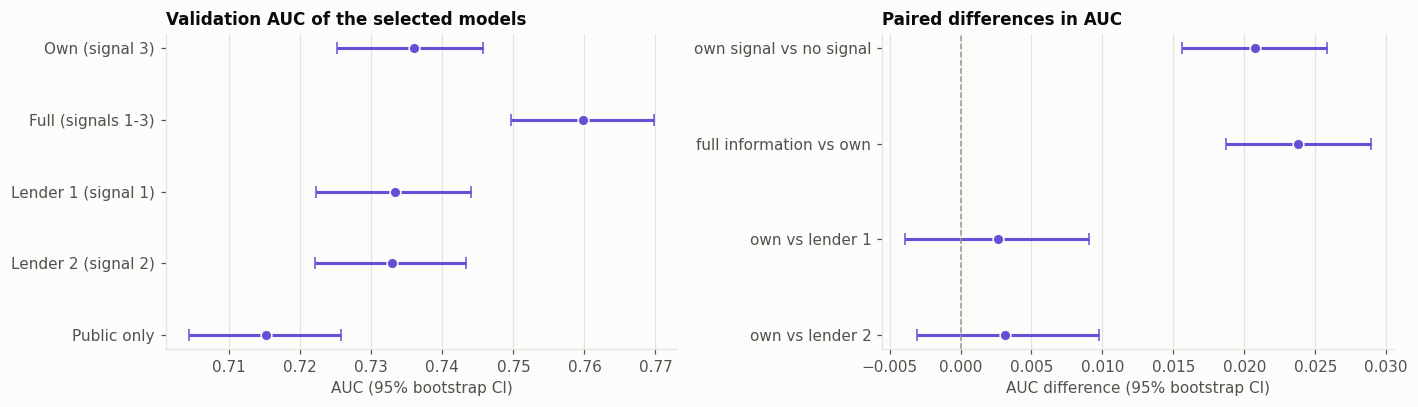

In [42]:
p_val = pd.DataFrame({i: VAL[i][m] for i, m in SELECTED.items()})
p_oof = pd.DataFrame({i: OOF[i][m] for i, m in SELECTED.items()})

auc_ci = pd.DataFrame({mp.INFO_SET_LABELS[i]: ev.bootstrap_ci(y_val, p_val[i]) for i in INFORMATION_SETS}).T

pairs = [("own", "public", "own signal vs no signal"),
         ("full", "own", "full information vs own"),
         ("own", "lender1", "own vs lender 1"),
         ("own", "lender2", "own vs lender 2")]
diff_rows = {}
for a, b, label in pairs:
    au = ev.bootstrap_diff_ci(y_val, p_val[a], p_val[b], metric=ev.auc)
    ll = ev.bootstrap_diff_ci(y_val, p_val[a], p_val[b], metric=ev.logloss)
    diff_rows[label] = {"AUC diff": au["estimate"], "AUC low": au["lower"], "AUC high": au["upper"],
                        "logloss diff": ll["estimate"], "logloss low": ll["lower"], "logloss high": ll["upper"]}
info_diffs = pd.DataFrame(diff_rows).T
display(info_diffs)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
mp.plot_interval(auc_ci, axes[0], "Validation AUC of the selected models", "AUC (95% bootstrap CI)")
mp.plot_interval(info_diffs.rename(columns={"AUC diff": "estimate", "AUC low": "lower", "AUC high": "upper"}),
                 axes[1], "Paired differences in AUC", "AUC difference (95% bootstrap CI)", reference=0)
fig.tight_layout()
plt.show()

**What information is worth** (selected models, validation set, paired bootstrap):

* **Our signal is worth about +0.021 AUC** over the public variables alone (95% CI [0.016, 0.026]),
  and reduces log-loss by 0.005. It is real and significant, but much smaller than what income
  already gives.
* **The two competitors' signals together are worth a further +0.024 AUC** (full vs own, CI
  [0.019, 0.029]). The full-information model is clearly better than ours: there is a lot of risk
  information we do not see and the competitors do.
* **We are neither better nor worse informed than lender 1 or lender 2**: the differences (+0.003 AUC)
  are not significant. All three lenders have models of the same quality, built on different signals.

### 6.5 Should we recalibrate?

A Platt recalibration $\text{logit}(p_{cal}) = a + b\,\text{logit}(p)$ is fitted on the
out-of-fold predictions of the training set and applied to the validation predictions. If it does
not improve validation log-loss, we keep the raw predictions.

In [43]:
rows = {}
for info, m in SELECTED.items():
    cal = fit_calibrator(p_oof[info], y_train, method="platt")
    p_cal = cal.predict(p_val[info])
    raw, new = ev.compute_metrics(y_val, p_val[info]), ev.compute_metrics(y_val, p_cal)
    rows[info] = {"Platt a": cal.intercept_, "Platt b": cal.slope_,
                  "val logloss raw": raw["logloss"], "val logloss recalibrated": new["logloss"],
                  "val slope raw": raw["calib_slope"], "val slope recalibrated": new["calib_slope"]}
pd.DataFrame(rows).T

,Platt a,Platt b,val logloss raw,val logloss recalibrated,val slope raw,val slope recalibrated
own,-0.0094,0.9950,0.2909,0.2909,0.9909,0.9959
full,-0.0133,0.9927,0.2824,0.2824,1.0123,1.0197
lender1,-0.0113,0.9941,0.2912,0.2912,0.9871,0.9930
lender2,-0.0109,0.9942,0.2915,0.2915,0.9868,0.9925
public,-0.0086,0.9955,0.2961,0.2961,0.9650,0.9693


**No recalibration is needed.** The Platt parameters estimated on the out-of-fold predictions are
essentially the identity ($a \approx -0.01$, $b \approx 0.995$), and applying them leaves the validation
log-loss unchanged to four decimals. The selected models are already well calibrated, so we use their
raw probabilities.

### 6.6 How differently the lenders see the same applicants

Correlation between the selected models' predictions on the validation set, and our predictions
plotted against lender 1's and against the full-information model's.

,Own (signal 3),Full (signals 1-3),Lender 1 (signal 1),Lender 2 (signal 2),Public only
Own (signal 3),1.000,0.867,0.823,0.831,0.904
Full (signals 1-3),0.867,1.000,0.866,0.858,0.781
Lender 1 (signal 1),0.823,0.866,1.000,0.830,0.903
Lender 2 (signal 2),0.831,0.858,0.830,1.000,0.912
Public only,0.904,0.781,0.903,0.912,1.000


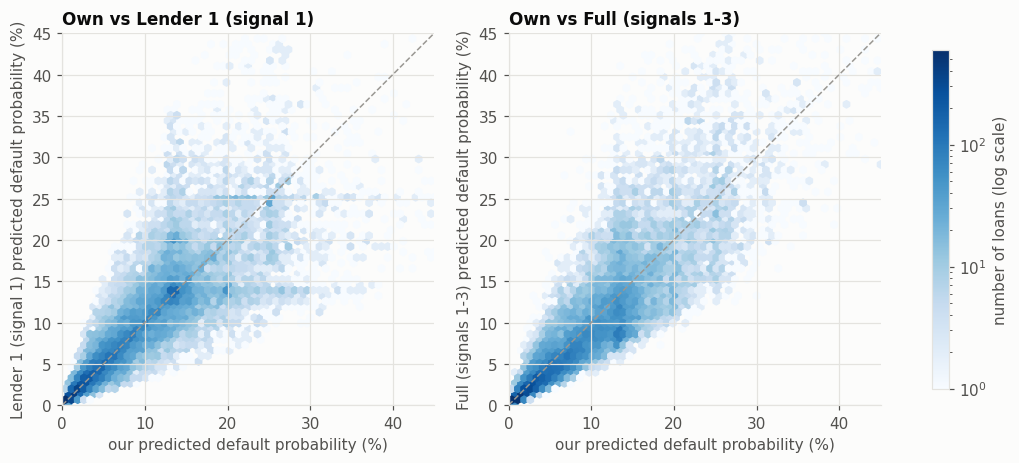

In [44]:
display(p_val.rename(columns=mp.INFO_SET_LABELS).corr().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, other in zip(axes, ["lender1", "full"]):
    hb = ax.hexbin(100 * p_val["own"], 100 * p_val[other], gridsize=60, bins="log",
                   cmap="Blues", mincnt=1, extent=(0, 45, 0, 45))
    ax.plot([0, 45], [0, 45], color=mp.REFERENCE, lw=1, ls="--")
    ax.set_xlim(0, 45); ax.set_ylim(0, 45); ax.set_aspect("equal")
    ax.set_xlabel("our predicted default probability (%)")
    ax.set_ylabel(f"{mp.INFO_SET_LABELS[other]} predicted default probability (%)")
    ax.set_title(f"Own vs {mp.INFO_SET_LABELS[other]}")
fig.colorbar(hb, ax=axes, label="number of loans (log scale)", shrink=0.8)
plt.show()

**The lenders see the same applicants quite differently.** Our predictions correlate at only 0.82-0.83
with lender 1's and lender 2's, and at 0.87 with the full-information model's. In the scatter plots,
applicants we put at 10% are commonly anywhere between about 5% and 20% for lender 1.

For any given applicant, each lender holds a different noisy estimate
of the same risk. When prices follow these estimates, the borrower goes to whoever is the most
optimistic, and that is the lender most likely to be wrong in the borrower's favour.

### 6.7 Preview of the winner's curse

If every lender priced at its own break-even rate, each borrower would (preferences aside) pick
the lender with the **lowest** predicted default probability. Here we split the validation loans
by which of the three lenders' models is the most optimistic, and compare *our* average prediction
with the observed default rate in each group. Part 5 measures this properly with the market
simulator; this is only a first look at why our predictions cannot be used as prices directly.

,loans,our_mean_p,observed,gap (observed - ours)
group,,,,
we are most optimistic,"6,657",8.00%,10.06%,+2.07%
lender 1 most optimistic,"6,939",10.91%,10.13%,-0.78%
lender 2 most optimistic,"6,404",10.97%,9.62%,-1.35%


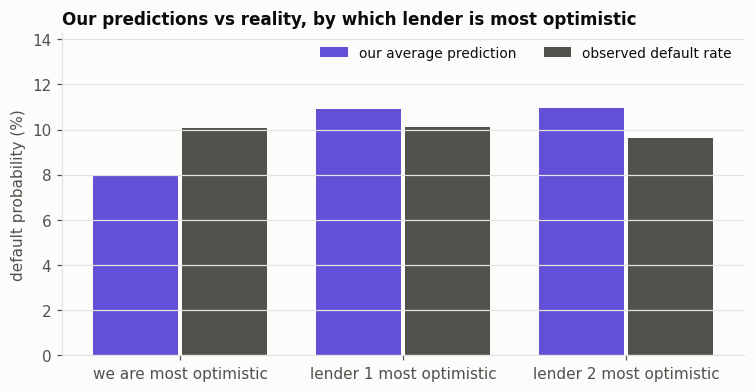

In [45]:
GROUPS = {"own": "we are most optimistic", "lender1": "lender 1 most optimistic",
          "lender2": "lender 2 most optimistic"}
lenders = p_val[["own", "lender1", "lender2"]]
most_optimistic = lenders.idxmin(axis=1).map(GROUPS)
curse = (pd.DataFrame({"group": most_optimistic, "our p": p_val["own"], "default": y_val})
         .groupby("group")
         .agg(loans=("default", "size"), our_mean_p=("our p", "mean"), observed=("default", "mean"))
         .reindex(GROUPS.values()))
curse["gap (observed - ours)"] = curse["observed"] - curse["our_mean_p"]
display(curse.style.format({"loans": "{:,}", "our_mean_p": "{:.2%}", "observed": "{:.2%}",
                            "gap (observed - ours)": "{:+.2%}"}))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(curse))
ax.bar(x - 0.2, 100 * curse["our_mean_p"], 0.38, color=mp.SINGLE_COLOR, label="our average prediction")
ax.bar(x + 0.2, 100 * curse["observed"], 0.38, color=mp.INK_SECONDARY, label="observed default rate")
ax.set_xticks(x, curse.index)
ax.grid(axis="x", visible=False)
ax.set_ylabel("default probability (%)")
ax.set_ylim(0, 100 * curse[["our_mean_p", "observed"]].max().max() * 1.3)
ax.set_title("Our predictions vs reality, by which lender is most optimistic")
ax.legend(loc="upper right", ncols=2)
plt.show()

**This is the winner's curse, already visible in the predictions.** On the validation set, our model
is the most optimistic of the three lenders for 6,657 borrowers (one third). For them we predict an
average default rate of **8.0%**, but **10.1%** actually default: we under-predict their risk by about
2.1 percentage points, about a fifth of the true rate.

Our model is not biased: it is well calibrated over all borrowers. The problem is **selection**. A
borrower for whom our estimate is the lowest is disproportionately one whose risk we under-estimated.
For the borrowers where a competitor is the most optimistic, we are too pessimistic (11.0% predicted vs
9.6-10.1% observed), but under break-even pricing we would not win them anyway.

Consequence for the next parts: pricing at our own break-even rate $p/(1-p)$ would lose money on the
loans we actually win. Part 5 measures this gap with the market simulator, and Part 6 designs a
pricing rule that corrects it.

### 6.8 Deliverables

Saved to `data/predictions/` (indexed by `row_id` for past loans, `id` for applications):

| file | content |
|---|---|
| `train_oof.csv` | `default` + the 15 out-of-fold predictions (`<info set>__<model>`) |
| `validation.csv` | `default` + the 15 validation predictions, from models fitted on train only |
| `train_oof_selected.csv` | `default` + `p_own`, `p_full`, `p_lender1`, `p_lender2`, `p_public` (selected models) |
| `validation_selected.csv` | the same on the validation set — the main input of Parts 3 to 6 |
| `applications_own.csv` | `p_own` for the 100,000 new applicants |

In [46]:
renamed = {i: f"p_{i}" for i in INFORMATION_SETS}
paths = [
    save_predictions(oof_all, "train_oof.csv", y=y_train),
    save_predictions(val_all, "validation.csv", y=y_val),
    save_predictions(p_oof.rename(columns=renamed), "train_oof_selected.csv", y=y_train),
    save_predictions(p_val.rename(columns=renamed), "validation_selected.csv", y=y_val),
]
for path in paths:
    print(f"saved {path.relative_to(path.parents[2])}")

saved data/predictions/train_oof.csv
saved data/predictions/validation.csv
saved data/predictions/train_oof_selected.csv
saved data/predictions/validation_selected.csv


**Predictions for the new applications.** The selected own model (spline logistic) is refitted on
**train + validation (all 100,000 past loans)** with the same settings, so that the final model uses
all the data. Validation was only needed to choose and check the model. As a sanity check we compare
its predictions with the train-only model's and with the validation predictions.

In [47]:
own_model = SELECTED["own"]
X_apps = get_X(data, own_model, "own", "applications")

# Final model: selected family and settings, refitted on train + validation (100,000 loans).
final_model = fit_models(data, "own", [own_model], fit_on="train+validation")[own_model]
p_apps = pd.Series(predict_default(final_model, X_apps), index=X_apps.index, name="p_own")

# Check: the same model fitted on train only gives almost the same predictions.
train_only = fit_models(data, "own", [own_model], fit_on="train")[own_model]
p_apps_train_only = predict_default(train_only, X_apps)

checks = pd.DataFrame({
    "applications (final model)": p_apps.describe(percentiles=[.01, .1, .5, .9, .99]),
    "validation (train-only model)": p_val["own"].describe(percentiles=[.01, .1, .5, .9, .99]),
}).drop("count")
display(checks.style.format("{:.4f}"))
print(f"correlation with the train-only model's predictions : {np.corrcoef(p_apps, p_apps_train_only)[0, 1]:.4f}")
print(f"mean absolute difference                              : {np.abs(p_apps - p_apps_train_only).mean():.5f}")
print(f"applicants with p >= 0.5 (no offer at break-even)     : {(p_apps >= 0.5).sum()}")
print(f"applicants with p >= 0.3                              : {(p_apps >= 0.3).sum():,}")

path = save_predictions(p_apps.to_frame(), "applications_own.csv")
print(f"\nsaved {path.relative_to(path.parents[2])}: {len(p_apps):,} applicants")

,applications (final model),validation (train-only model)
mean,0.0996,0.0996
std,0.0774,0.0769
min,0.0001,0.0001
1%,0.0009,0.0009
10%,0.0129,0.0126
50%,0.0867,0.0871
90%,0.2045,0.2036
99%,0.3369,0.3286
max,0.5020,0.4647


correlation with the train-only model's predictions : 0.9996
mean absolute difference                              : 0.00147
applicants with p >= 0.5 (no offer at break-even)     : 1
applicants with p >= 0.3                              : 1,820

saved data/predictions/applications_own.csv: 100,000 applicants


### 6.9 Conclusions


1. **Model.** A spline logistic regression is selected for every information set. All three model
   families perform almost identically (within 0.001 log-loss); the spline is best or tied-best,
   well calibrated, and keeps an explicit formula. Gradient boosting brings no gain: the data are
   close to additive in the log-odds.
2. **What predicts default.** Income, by far, and whether the applicant has any income at all. Then
   the private signal (higher = safer, with average risk when the signal is missing), then
   employment status. Sex and marital status carry almost no information once income is known.
3. **Our model.** Validation AUC 0.736, log-loss 0.2909, calibration slope 0.99, average prediction
   equal to the default rate. No recalibration needed.
4. **Information.** Our signal adds +0.021 AUC over public data. Lenders 1 and 2 are as well informed
   as we are, with different signals; the full-information model is clearly better (+0.024 AUC over
   ours).
5. **Strategic warning.** Each lender's estimates are good on average but disagree on individual
   applicants (correlation about 0.82). The borrowers for whom we are the most optimistic default at
   10.1% while we predict 8.0%: pricing at our break-even rate would suffer the winner's curse. Our
   predictions are an input to pricing, not the price.
6. **Deliverables** are in `data/predictions/`: out-of-fold and validation predictions of all 15
   models, the selected models' predictions (`p_own`, `p_full`, `p_lender1`, `p_lender2`, `p_public`)
   for Parts 3 to 7, and `p_own` for the 100,000 new applicants. Their predicted default rate is
   9.96%, the same distribution as on validation. One applicant reaches p >= 0.5 (no offer at
   break-even), and 1,820 have p >= 0.3.

**Limitations.** The competitor models are our reconstruction; the real lenders 1 and 2 may use other
models or deliberately shade their estimates, which Part 7 tests with scenarios. The validation set
(20,000 loans, about 2,000 defaults) gives paired AUC intervals about ±0.006 wide between information sets, so smaller differences cannot be detected. Predictions
for very high incomes are close to 0 and rest on few observations (no defaults above EUR 125k in the
data), so pricing should not go to zero for them.